# 03. Machine Learning Model Development

## Explainable AI for Network Intrusion Detection

### Dataset: CICIDS2017

## 1. Introduction

This notebook focuses on the development and evaluation
of machine learning models for network intrusion
detection using the preprocessed CICIDS2017 dataset.

The dataset consists of 2,520,798 network traffic
records, 69 input features and 15 traffic classes,
including benign traffic and 14 attack categories.

The preprocessing artifacts generated in Notebook 02
provide the foundation for reproducible machine
learning experimentation.

Both standardized and unscaled feature representations
are retained to accommodate the requirements of
different machine learning algorithms.

Particular attention is given to class imbalance,
minority attack detection, computational efficiency,
data leakage prevention and model interpretability.

The experimental process aims to identify suitable
machine learning models for subsequent explainable
artificial intelligence analysis.

## 2. Experimental Objectives

The primary objective of this notebook is to develop
and systematically evaluate machine learning models
for multiclass network intrusion detection.

The specific experimental objectives are to:

1. Establish a reproducible machine learning
   experimental environment.

2. Load and verify the preprocessing artifacts
   generated in Notebook 02.

3. Establish a validation strategy that maintains
   separation between model development and final
   testing.

4. Develop baseline machine learning models for
   multiclass network traffic classification.

5. Investigate the impact of class imbalance on
   intrusion detection performance.

6. Compare weighted and unweighted machine
   learning approaches.

7. Evaluate model performance using accuracy,
   precision, recall, F1-score, balanced accuracy
   and confusion matrices.

8. Examine minority attack detection performance
   and benign traffic false positive rates.

9. Assess computational efficiency, including
   training time and prediction time.

10. Identify suitable machine learning models
    for subsequent explainable AI analysis.

11. Preserve trained models, experimental
    configurations and evaluation results
    to support reproducibility.

The final testing dataset will remain independent
of model training, validation and hyperparameter
selection.

## 3. Experimental Environment Configuration

This section establishes the computational environment
required for reproducible machine learning experimentation.

The hardware specifications, Python environment and
installed library versions are examined to assess
computational capacity and software compatibility.

Available memory and processing resources will guide
model configuration, parallel processing and
memory-efficient training strategies.

A fixed random seed will be maintained throughout
the experimental process to improve reproducibility.

### 3A. System and Hardware Information

The computational environment is examined to determine
the operating system, processor architecture, CPU
capacity, available memory and Python version.

import os
import sys
import platform
import shutil
import importlib.util

print("SYSTEM AND HARDWARE INFORMATION")
print("-" * 60)

print("Operating system:", platform.system())
print("OS version:", platform.version())
print("Architecture:", platform.machine())
print("Processor:", platform.processor())
print("Logical CPU cores:", os.cpu_count())
print("Python version:", platform.python_version())
print("Python executable:", sys.executable)

if importlib.util.find_spec("psutil") is not None:
    import psutil

    memory = psutil.virtual_memory()

    print("Physical CPU cores:", psutil.cpu_count(logical=False))
    print(f"Total RAM: {memory.total / (1024**3):.2f} GB")
    print(f"Available RAM: {memory.available / (1024**3):.2f} GB")
    print(f"Memory usage: {memory.percent}%")
else:
    print("psutil is not installed.")
    print("RAM information requires additional verification.")

disk = shutil.disk_usage(os.getcwd())

print(f"Total disk space: {disk.total / (1024**3):.2f} GB")
print(f"Available disk space: {disk.free / (1024**3):.2f} GB")

print("-" * 60)
print("System information collection completed.")

### 3C. Software Library Version Verification

The installed software libraries are examined to
establish the computational dependencies required
for machine learning experimentation.

Library versions are documented to support
experimental reproducibility, software compatibility
and future replication of the research workflow.

The verification covers numerical computation,
data manipulation, machine learning, statistical
analysis, visualization, model persistence and
explainable artificial intelligence.

In [4]:
from importlib.metadata import version, PackageNotFoundError
import pandas as pd

libraries = {
    "NumPy": "numpy",
    "Pandas": "pandas",
    "Scikit-learn": "scikit-learn",
    "SciPy": "scipy",
    "Matplotlib": "matplotlib",
    "Seaborn": "seaborn",
    "Joblib": "joblib",
    "XGBoost": "xgboost",
    "LightGBM": "lightgbm",
    "SHAP": "shap",
    "LIME": "lime",
    "Psutil": "psutil",
    "PyArrow": "pyarrow",
    "Imbalanced-learn": "imbalanced-learn",
    "Threadpoolctl": "threadpoolctl"
}

library_records = []

for library_name, package_name in libraries.items():

    try:
        installed_version = version(package_name)
        status = "Installed"

    except PackageNotFoundError:
        installed_version = "Not available"
        status = "Not installed"

    library_records.append({
        "Library": library_name,
        "Package": package_name,
        "Version": installed_version,
        "Status": status
    })

library_verification_df = pd.DataFrame(library_records)

print("SOFTWARE LIBRARY VERSION VERIFICATION")
print("-" * 65)

display(library_verification_df)

installed_count = (
    library_verification_df["Status"] == "Installed"
).sum()

print("Total libraries examined:", len(libraries))
print("Installed libraries:", installed_count)
print("Missing libraries:", len(libraries) - installed_count)

print("\nLibrary version verification completed.")

SOFTWARE LIBRARY VERSION VERIFICATION
-----------------------------------------------------------------


,Library,Package,Version,Status
0,NumPy,numpy,2.4.6,Installed
1,Pandas,pandas,3.1.1,Installed
2,Scikit-learn,scikit-learn,1.9.1,Installed
3,SciPy,scipy,1.15.3,Installed
4,Matplotlib,matplotlib,3.11.2,Installed
5,Seaborn,seaborn,0.13.2,Installed
6,Joblib,joblib,1.6.0,Installed
7,XGBoost,xgboost,3.4.1,Installed
8,LightGBM,lightgbm,4.7.0,Installed
9,SHAP,shap,0.54.1,Installed


Total libraries examined: 15
Installed libraries: 13
Missing libraries: 2

Library version verification completed.


### 3E. Additional Machine Learning Dependencies

The software environment is extended to include
XGBoost and LightGBM for comparative machine
learning experimentation.

These libraries provide gradient boosting
implementations suitable for structured data
classification and large-scale intrusion
detection experiments.

Additional dependencies will be introduced only
when required by the experimental methodology
to maintain a controlled computational environment.

In [5]:
%pip install xgboost lightgbm

Note: you may need to restart the kernel to use updated packages.


In [6]:
import xgboost
import lightgbm
import sklearn
import numpy as np
import pandas as pd
import shap

print("DEPENDENCY COMPATIBILITY VERIFICATION")
print("-" * 60)

print("XGBoost version:", xgboost.__version__)
print("LightGBM version:", lightgbm.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("SHAP version:", shap.__version__)

print("-" * 60)
print("All selected libraries imported successfully.")

DEPENDENCY COMPATIBILITY VERIFICATION
------------------------------------------------------------
XGBoost version: 3.4.1
LightGBM version: 4.7.0
Scikit-learn version: 1.9.1
NumPy version: 2.4.6
Pandas version: 3.1.1
SHAP version: 0.54.1
------------------------------------------------------------
All selected libraries imported successfully.


### 3H. Notebook Progress Monitoring Support

Text-based progress monitoring is configured
to support the observation of computationally
intensive machine learning experiments.

This approach provides progress information
without relying on interactive notebook widgets.

The configuration supports computational
monitoring without modifying the dataset
or experimental methodology.

In [7]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [8]:
import ipywidgets
import tqdm

from tqdm import tqdm as text_tqdm
from time import sleep

print("PROGRESS MONITORING VERIFICATION")
print("-" * 60)

print("IPyWidgets version:", ipywidgets.__version__)
print("Tqdm version:", tqdm.__version__)

print("Monitoring mode: Text-based")

print("\nTesting progress monitoring:")

for i in text_tqdm(
    range(10),
    desc="Verification",
    ncols=80
):
    sleep(0.1)

print("\nProgress monitoring test completed successfully.")

PROGRESS MONITORING VERIFICATION
------------------------------------------------------------
IPyWidgets version: 8.1.9
Tqdm version: 4.70.1
Monitoring mode: Text-based

Testing progress monitoring:


Verification: 100%|█████████████████████████████| 10/10 [00:01<00:00,  9.83it/s]


Progress monitoring test completed successfully.


### 3K. Final Computational Environment Documentation

The final computational environment is documented
following the installation and verification of
additional machine learning dependencies.

A complete inventory of installed Python packages
and their versions is preserved to support
experimental reproducibility, dependency tracking
and future replication.

The environment documentation provides a reference
for subsequent model development, performance
evaluation and explainable AI analysis.

In [9]:
import sys
import subprocess
from pathlib import Path
from datetime import datetime
from importlib.metadata import version

project_root = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

environment_dir = project_root / "environment"

environment_dir.mkdir(
    parents=True,
    exist_ok=True
)

requirements_path = (
    environment_dir / "03_requirements.txt"
)

# Capture the complete installed package inventory
result = subprocess.run(
    [sys.executable, "-m", "pip", "freeze"],
    capture_output=True,
    text=True,
    check=True
)

requirements_path.write_text(
    result.stdout,
    encoding="utf-8"
)

package_count = len([
    line for line in result.stdout.splitlines()
    if line.strip()
])

# Verify selected research dependencies
selected_packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "scipy",
    "xgboost",
    "lightgbm",
    "shap",
    "joblib",
    "psutil",
    "pyarrow",
    "tqdm",
    "ipywidgets"
]

print("FINAL COMPUTATIONAL ENVIRONMENT")
print("-" * 60)

print("Documentation date:", datetime.now())
print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)

print("\nSELECTED RESEARCH DEPENDENCIES")
print("-" * 60)

for package in selected_packages:
    print(f"{package}: {version(package)}")

print("\nENVIRONMENT PERSISTENCE")
print("-" * 60)

print("Total package entries:", package_count)
print("Requirements file:", requirements_path)
print("File exists:", requirements_path.exists())
print("File size:", requirements_path.stat().st_size, "bytes")

print("\nEnvironment documentation completed.")

FINAL COMPUTATIONAL ENVIRONMENT
------------------------------------------------------------
Documentation date: 2026-11-24 14:04:24.326572
Python version: 3.12.10
Python executable: C:\Users\pc\XAI-Intrusion-Detection\.venv\Scripts\python.exe

SELECTED RESEARCH DEPENDENCIES
------------------------------------------------------------
numpy: 2.4.6
pandas: 3.1.1
scikit-learn: 1.9.1
scipy: 1.15.3
xgboost: 3.4.1
lightgbm: 4.7.0
shap: 0.54.1
joblib: 1.6.0
psutil: 7.2.2
pyarrow: 26.0.1
tqdm: 4.70.1
ipywidgets: 8.1.9

ENVIRONMENT PERSISTENCE
------------------------------------------------------------
Total package entries: 116
Requirements file: C:\Users\pc\XAI-Intrusion-Detection\environment\03_requirements.txt
File exists: True
File size: 2245 bytes

Environment documentation completed.


## 4. Experimental Configuration

The experimental configuration establishes a
consistent and reproducible framework for machine
learning model development and evaluation.

A fixed random seed is adopted to improve
experimental reproducibility.

Computational resource limits are established
to manage memory consumption and processor
utilization during large-scale experimentation.

A separate validation dataset will be derived
from the existing training dataset to support
model selection and hyperparameter evaluation.

The independent testing dataset will remain
excluded from model training, validation and
hyperparameter selection.

Model performance will be assessed using
multiple evaluation metrics, with particular
attention to minority attack detection,
class imbalance and false positive rates.

In [10]:
import os
import random
import numpy as np
import psutil

# Reproducibility settings
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

# Validation configuration
VALIDATION_SIZE = 0.20

# Dataset configuration
EXPECTED_FEATURES = 69
EXPECTED_CLASSES = 15
EXPECTED_TOTAL_RECORDS = 2520798

# Computational resource configuration
LOGICAL_CORES = os.cpu_count() or 1

N_JOBS = min(4, LOGICAL_CORES)

TOTAL_RAM_GB = (
    psutil.virtual_memory().total / (1024 ** 3)
)

AVAILABLE_RAM_GB = (
    psutil.virtual_memory().available / (1024 ** 3)
)

# Primary model selection metric
PRIMARY_METRIC = "f1_macro"

print("GLOBAL EXPERIMENTAL CONFIGURATION")
print("-" * 60)

print("Random state:", RANDOM_STATE)
print("Validation proportion:", VALIDATION_SIZE)
print("Expected input features:", EXPECTED_FEATURES)
print("Expected traffic classes:", EXPECTED_CLASSES)
print("Expected total records:", EXPECTED_TOTAL_RECORDS)

print("\nCOMPUTATIONAL RESOURCE CONFIGURATION")
print("-" * 60)

print("Available logical CPU cores:", LOGICAL_CORES)
print("Configured parallel jobs:", N_JOBS)
print("Total RAM (GB):", round(TOTAL_RAM_GB, 2))
print("Available RAM (GB):", round(AVAILABLE_RAM_GB, 2))

print("\nMODEL SELECTION CONFIGURATION")
print("-" * 60)

print("Primary evaluation metric:", PRIMARY_METRIC)

print("\nExperimental configuration completed.")

GLOBAL EXPERIMENTAL CONFIGURATION
------------------------------------------------------------
Random state: 42
Validation proportion: 0.2
Expected input features: 69
Expected traffic classes: 15
Expected total records: 2520798

COMPUTATIONAL RESOURCE CONFIGURATION
------------------------------------------------------------
Available logical CPU cores: 8
Configured parallel jobs: 4
Total RAM (GB): 31.69
Available RAM (GB): 24.41

MODEL SELECTION CONFIGURATION
------------------------------------------------------------
Primary evaluation metric: f1_macro

Experimental configuration completed.


### 4C. Experimental Configuration Persistence

The global experimental settings are preserved
in a structured configuration file to support
reproducibility, experimental consistency and
future verification.

The configuration records the random seed,
validation proportion, dataset characteristics,
computational resource allocation and primary
model selection metric.

Preserving these settings supports consistent
experimental conditions across subsequent
machine learning models.

In [11]:
import json
from pathlib import Path

# Define project directory
PROJECT_ROOT = Path.home() / "XAI-Intrusion-Detection"

# Define configuration directory
CONFIG_DIR = PROJECT_ROOT / "config"
CONFIG_DIR.mkdir(parents=True, exist_ok=True)

# Experimental configuration
experimental_config = {
    "dataset": "CICIDS2017",
    "random_state": RANDOM_STATE,
    "validation_size": VALIDATION_SIZE,
    "expected_features": EXPECTED_FEATURES,
    "expected_classes": EXPECTED_CLASSES,
    "expected_total_records": EXPECTED_TOTAL_RECORDS,
    "logical_cpu_cores": LOGICAL_CORES,
    "parallel_jobs": N_JOBS,
    "total_ram_gb": round(TOTAL_RAM_GB, 2),
    "primary_metric": PRIMARY_METRIC
}

# Configuration file path
config_path = CONFIG_DIR / "03_experimental_config.json"

# Save configuration
with open(config_path, "w", encoding="utf-8") as file:
    json.dump(experimental_config, file, indent=4)

# Reload configuration for verification
with open(config_path, "r", encoding="utf-8") as file:
    loaded_config = json.load(file)

# Verification
print("EXPERIMENTAL CONFIGURATION PERSISTENCE")
print("-" * 60)

print("Configuration directory:", CONFIG_DIR)
print("Configuration file:", config_path)
print("Total configuration parameters:", len(experimental_config))
print("File exists:", config_path.exists())
print("File size (bytes):", config_path.stat().st_size)
print("Configuration integrity verified:",
      loaded_config == experimental_config)

print("-" * 60)
print("Experimental configuration saved successfully.")

EXPERIMENTAL CONFIGURATION PERSISTENCE
------------------------------------------------------------
Configuration directory: C:\Users\pc\XAI-Intrusion-Detection\config
Configuration file: C:\Users\pc\XAI-Intrusion-Detection\config\03_experimental_config.json
Total configuration parameters: 10
File exists: True
File size (bytes): 303
Configuration integrity verified: True
------------------------------------------------------------
Experimental configuration saved successfully.


## 5. Preprocessing Artifact Discovery and Verification

This section identifies and verifies the preprocessing
artifacts generated in Notebook 02.

The objective is to establish a reliable connection
between the data preprocessing pipeline and the
machine learning development environment.

### 5A. Preprocessing Artifact Discovery

Previously generated preprocessing artifacts are
identified within the project directory.

The discovery process establishes the availability,
location and storage requirements of the files
required for subsequent machine learning experiments.

In [12]:
from pathlib import Path
import pandas as pd

# Locate preprocessing artifacts
artifact_files = sorted(
    path for path in PROJECT_ROOT.rglob("02_*")
    if path.is_file()
    and ".venv" not in path.parts
    and ".git" not in path.parts
    and ".ipynb_checkpoints" not in path.parts
    and path.suffix != ".ipynb"
)

# Create artifact inventory
artifact_records = []


for path in artifact_files:
    artifact_records.append({
        "Filename": path.name,
        "Relative_Path": str(
            path.relative_to(PROJECT_ROOT)
        ),
        "File_Type": path.suffix,
        "Size_MB": round(
            path.stat().st_size / (1024 ** 2), 6
        ),
        "Exists": path.exists()
    })

artifact_inventory = pd.DataFrame(
    artifact_records,
    columns=[
        "Filename",
        "Relative_Path",
        "File_Type",
        "Size_MB",
        "Exists"
    ]
)

print("PREPROCESSING ARTIFACT DISCOVERY")
print("-" * 60)

print("Project directory:", PROJECT_ROOT)
print("Total artifacts discovered:", len(artifact_inventory))

display(artifact_inventory)

print("-" * 60)

print(
    "Total artifact size (MB):",
    round(artifact_inventory["Size_MB"].sum(), 2)
)

print(
    "Artifact discovery successful:",
    not artifact_inventory.empty
)

PREPROCESSING ARTIFACT DISCOVERY
------------------------------------------------------------
Project directory: C:\Users\pc\XAI-Intrusion-Detection
Total artifacts discovered: 28


,Filename,Relative_Path,File_Type,Size_MB,Exists
0,02_Data_Preprocessing_and_Model_Preparation,02_Data_Preprocessing_and_Model_Preparation,,0.212589,True
1,02_artifact_verification.csv,results\02_artifact_verification.csv,.csv,0.000296,True
2,02_class_representation_verification.csv,results\02_class_representation_verification.csv,.csv,0.000684,True
3,02_class_weight_verification.csv,results\02_class_weight_verification.csv,.csv,0.000985,True
4,02_class_weights.csv,results\02_class_weights.csv,.csv,0.000541,True
5,02_class_weights.joblib,results\02_class_weights.joblib,.joblib,0.000173,True
6,02_feature_names.json,results\02_feature_names.json,.json,0.001616,True
7,02_feature_scale_analysis.csv,results\02_feature_scale_analysis.csv,.csv,0.005260,True
8,02_final_dataset_summary.csv,results\02_final_dataset_summary.csv,.csv,0.000296,True
9,02_final_readiness_checks.csv,results\02_final_readiness_checks.csv,.csv,0.000549,True


------------------------------------------------------------
Total artifact size (MB): 702.22
Artifact discovery successful: True


### 5B. Essential Preprocessing Artifact Verification

The essential preprocessing artifacts required
for machine learning development are identified
and verified.

These artifacts include standardized feature
datasets, encoded target variables, dataset
partition indices, feature metadata, class
weights, missing-value replacement parameters
and the fitted standardization transformer.

Verification of artifact availability and file
integrity at the storage level establishes the
foundation for controlled dataset loading.

Detailed content validation will be performed
during subsequent verification stages.


In [13]:
# Essential preprocessing artifact verification

RESULTS_DIR = PROJECT_ROOT / "results"

essential_artifacts = {
    "Scaled training features":
        "02_X_train_scaled.npy",

    "Scaled testing features":
        "02_X_test_scaled.npy",

    "Training targets":
        "02_y_train.npy",

    "Testing targets":
        "02_y_test.npy",

    "Training indices":
        "02_train_indices.npy",

    "Testing indices":
        "02_test_indices.npy",

    "Feature names":
        "02_feature_names.json",

    "Label encoder":
        "02_label_encoder.joblib",

    "Class weights":
        "02_class_weights.joblib",

    "Median replacement values":
        "02_replacement_values.joblib",

    "StandardScaler":
        "02_standard_scaler.joblib"
}

essential_records = []

for artifact, filename in essential_artifacts.items():

    path = RESULTS_DIR / filename

    exists = path.is_file()

    size_bytes = path.stat().st_size if exists else 0

    essential_records.append({
        "Artifact": artifact,
        "Filename": filename,
        "Exists": exists,
        "Non_Empty": size_bytes > 0,
        "Size_MiB": round(
            size_bytes / (1024 ** 2), 6
        )
    })

essential_inventory = pd.DataFrame(
    essential_records
)

all_artifacts_available = bool(
    essential_inventory["Exists"].all()
)

all_artifacts_non_empty = bool(
    essential_inventory["Non_Empty"].all()
)

print("ESSENTIAL PREPROCESSING ARTIFACT VERIFICATION")
print("-" * 60)

display(essential_inventory)

print("-" * 60)

print("Required artifacts:",
      len(essential_artifacts))

print("Available artifacts:",
      essential_inventory["Exists"].sum())

print("Missing artifacts:",
      (~essential_inventory["Exists"]).sum())

print("All essential artifacts available:",
      all_artifacts_available)

print("All essential artifacts non-empty:",
      all_artifacts_non_empty)

print("Total essential artifact size (MiB):",
      round(essential_inventory["Size_MiB"].sum(), 2))

print("Artifact availability verification passed:",
      all_artifacts_available and all_artifacts_non_empty)

ESSENTIAL PREPROCESSING ARTIFACT VERIFICATION
------------------------------------------------------------


,Artifact,Filename,Exists,Non_Empty,Size_MiB
0,Scaled training features,02_X_train_scaled.npy,True,True,530.807701
1,Scaled testing features,02_X_test_scaled.npy,True,True,132.702148
2,Training targets,02_y_train.npy,True,True,15.385849
3,Testing targets,02_y_test.npy,True,True,3.846558
4,Training indices,02_train_indices.npy,True,True,15.385849
5,Testing indices,02_test_indices.npy,True,True,3.846558
6,Feature names,02_feature_names.json,True,True,0.001616
7,Label encoder,02_label_encoder.joblib,True,True,0.000667
8,Class weights,02_class_weights.joblib,True,True,0.000173
9,Median replacement values,02_replacement_values.joblib,True,True,0.000264


------------------------------------------------------------
Required artifacts: 11
Available artifacts: 11
Missing artifacts: 0
All essential artifacts available: True
All essential artifacts non-empty: True
Total essential artifact size (MiB): 701.98
Artifact availability verification passed: True


### 5C. Memory-Efficient Dataset Loading

The standardized feature datasets, encoded
target variables and partition indices are
loaded from the verified preprocessing artifacts.

Memory mapping is employed to reduce immediate
memory consumption when accessing large
numerical arrays.

The original training and testing partitions
are preserved to maintain experimental
consistency and prevent unintended overlap
between model development and final evaluation.

Dataset dimensions, numerical data types and
storage requirements are examined before
subsequent content validation.

In [14]:
import numpy as np
import pandas as pd
import psutil

# Record memory availability before loading
memory_before = (
    psutil.virtual_memory().available / (1024 ** 3)
)

# Load standardized feature datasets
X_train_scaled = np.load(
    RESULTS_DIR / "02_X_train_scaled.npy",
    mmap_mode="r",
    allow_pickle=False
)

X_test_scaled = np.load(
    RESULTS_DIR / "02_X_test_scaled.npy",
    mmap_mode="r",
    allow_pickle=False
)

# Load encoded target variables
y_train = np.load(
    RESULTS_DIR / "02_y_train.npy",
    mmap_mode="r",
    allow_pickle=False
)

y_test = np.load(
    RESULTS_DIR / "02_y_test.npy",
    mmap_mode="r",
    allow_pickle=False
)

# Load original partition indices
train_indices = np.load(
    RESULTS_DIR / "02_train_indices.npy",
    mmap_mode="r",
    allow_pickle=False
)

test_indices = np.load(
    RESULTS_DIR / "02_test_indices.npy",
    mmap_mode="r",
    allow_pickle=False
)

# Dataset inventory
loaded_arrays = {
    "X_train_scaled": X_train_scaled,
    "X_test_scaled": X_test_scaled,
    "y_train": y_train,
    "y_test": y_test,
    "train_indices": train_indices,
    "test_indices": test_indices
}

loading_records = []

for name, array in loaded_arrays.items():

    loading_records.append({
        "Array": name,
        "Shape": str(array.shape),
        "Data_Type": str(array.dtype),
        "Dimensions": array.ndim,
        "Size_MiB": round(
            array.nbytes / (1024 ** 2), 2
        ),
        "Memory_Mapped": isinstance(
            array, np.memmap
        )
    })

loading_summary = pd.DataFrame(loading_records)

# Record memory availability after loading
memory_after = (
    psutil.virtual_memory().available / (1024 ** 3)
)

print("MEMORY-EFFICIENT DATASET LOADING")
print("-" * 60)

display(loading_summary)

print("-" * 60)

print("Total arrays loaded:", len(loaded_arrays))

print("Training records:", len(y_train))
print("Testing records:", len(y_test))

print("Total records:",
      len(y_train) + len(y_test))

print("Training features:",
      X_train_scaled.shape[1])

print("Testing features:",
      X_test_scaled.shape[1])

print("Available RAM before loading (GiB):",
      round(memory_before, 2))

print("Available RAM after loading (GiB):",
      round(memory_after, 2))

print("All arrays memory-mapped:",
      loading_summary["Memory_Mapped"].all())

print("-" * 60)
print("Dataset loading completed successfully.")

MEMORY-EFFICIENT DATASET LOADING
------------------------------------------------------------


,Array,Shape,Data_Type,Dimensions,Size_MiB,Memory_Mapped
0,X_train_scaled,"(2016638, 69)",float32,2,530.81,True
1,X_test_scaled,"(504160, 69)",float32,2,132.70,True
2,y_train,"(2016638,)",int64,1,15.39,True
3,y_test,"(504160,)",int64,1,3.85,True
4,train_indices,"(2016638,)",int64,1,15.39,True
5,test_indices,"(504160,)",int64,1,3.85,True


------------------------------------------------------------
Total arrays loaded: 6
Training records: 2016638
Testing records: 504160
Total records: 2520798
Training features: 69
Testing features: 69
Available RAM before loading (GiB): 24.41
Available RAM after loading (GiB): 24.41
All arrays memory-mapped: True
------------------------------------------------------------
Dataset loading completed successfully.


### 5D. Dataset Structural Validation

The loaded datasets are examined to verify
structural consistency with the preprocessing
outputs generated in Notebook 02.

Structural validation includes verification of
dataset dimensions, feature counts, target
alignment, partition sizes and numerical
data types.

These checks establish whether the loaded
datasets satisfy the expected structural
requirements for subsequent machine learning
experimentation.

Structural validation is performed before
numerical integrity assessment and model
development.

In [15]:
# Dataset structural validation

structural_checks = {
    "Training feature dimensions":
        X_train_scaled.ndim == 2,

    "Testing feature dimensions":
        X_test_scaled.ndim == 2,

    "Training target dimensions":
        y_train.ndim == 1,

    "Testing target dimensions":
        y_test.ndim == 1,

    "Training feature count":
        X_train_scaled.shape[1] == 69,

    "Testing feature count":
        X_test_scaled.shape[1] == 69,

    "Training feature-target alignment":
        X_train_scaled.shape[0] == len(y_train),

    "Testing feature-target alignment":
        X_test_scaled.shape[0] == len(y_test),

    "Training index alignment":
        len(train_indices) == len(y_train),

    "Testing index alignment":
        len(test_indices) == len(y_test),

    "Expected training records":
        len(y_train) == 2016638,

    "Expected testing records":
        len(y_test) == 504160,

    "Expected total records":
        len(y_train) + len(y_test) == 2520798,

    "Training feature data type":
        X_train_scaled.dtype == np.float32,

    "Testing feature data type":
        X_test_scaled.dtype == np.float32,

    "Training target data type":
        y_train.dtype == np.int64,

    "Testing target data type":
        y_test.dtype == np.int64,

    "Training index data type":
        train_indices.dtype == np.int64,

    "Testing index data type":
        test_indices.dtype == np.int64,

    "Training index dimensions":
        train_indices.ndim == 1,

    "Testing index dimensions":
        test_indices.ndim == 1
}

structural_validation = pd.DataFrame({
    "Validation_Check": list(structural_checks.keys()),
    "Passed": list(structural_checks.values())
})

structural_validation["Status"] = (
    structural_validation["Passed"]
    .map({True: "PASS", False: "FAIL"})
)

print("DATASET STRUCTURAL VALIDATION")
print("-" * 60)

display(structural_validation)

print("-" * 60)

print("Total structural checks:",
      len(structural_validation))

print("Passed checks:",
      structural_validation["Passed"].sum())

print("Failed checks:",
      (~structural_validation["Passed"]).sum())

structural_validation_passed = bool(
    structural_validation["Passed"].all()
)

print("Structural validation passed:",
      structural_validation_passed)

assert structural_validation_passed, (
    "Dataset structural validation failed."
)

print("-" * 60)
print("Dataset structural validation completed.")

DATASET STRUCTURAL VALIDATION
------------------------------------------------------------


,Validation_Check,Passed,Status
0,Training feature dimensions,True,PASS
1,Testing feature dimensions,True,PASS
2,Training target dimensions,True,PASS
3,Testing target dimensions,True,PASS
4,Training feature count,True,PASS
5,Testing feature count,True,PASS
6,Training feature-target alignment,True,PASS
7,Testing feature-target alignment,True,PASS
8,Training index alignment,True,PASS
9,Testing index alignment,True,PASS


------------------------------------------------------------
Total structural checks: 21
Passed checks: 21
Failed checks: 0
Structural validation passed: True
------------------------------------------------------------
Dataset structural validation completed.


### 5E. Dataset Numerical Integrity Verification

The training and testing datasets are examined
to verify numerical integrity before machine
learning model development.

The verification process identifies missing
values, positive infinity, negative infinity
and other non-finite numerical values.

Encoded target labels are also examined to
ensure consistency with the expected traffic
class representation.

A batch-based verification approach is adopted
to reduce memory consumption while examining
the complete feature datasets.

Successful numerical integrity verification
establishes that the datasets contain valid
numerical inputs for subsequent machine
learning experimentation.

In [16]:
# Dataset numerical integrity verification

from tqdm import tqdm
import sys

BATCH_SIZE = 100000

def verify_numerical_integrity(array, dataset_name):

    nan_count = 0
    positive_inf_count = 0
    negative_inf_count = 0
    non_finite_count = 0

    for start in tqdm(
        range(0, len(array), BATCH_SIZE),
        desc=f"Checking {dataset_name}",
        file=sys.stdout
    ):

        end = min(start + BATCH_SIZE, len(array))
        batch = array[start:end]

        nan_count += int(np.isnan(batch).sum())

        positive_inf_count += int(
            np.isposinf(batch).sum()
        )

        negative_inf_count += int(
            np.isneginf(batch).sum()
        )

        non_finite_count += int(
            (~np.isfinite(batch)).sum()
        )

    return {
        "Dataset": dataset_name,
        "Records": array.shape[0],
        "Features": array.shape[1],
        "Total_Values": array.size,
        "NaN_Count": nan_count,
        "Positive_Infinity": positive_inf_count,
        "Negative_Infinity": negative_inf_count,
        "Non_Finite_Count": non_finite_count,
        "Passed": non_finite_count == 0
    }


print("DATASET NUMERICAL INTEGRITY VERIFICATION")
print("-" * 60)

numerical_integrity = pd.DataFrame([
    verify_numerical_integrity(
        X_train_scaled, "Training"
    ),
    verify_numerical_integrity(
        X_test_scaled, "Testing"
    )
])

display(numerical_integrity)

# Encoded target verification

expected_labels = np.arange(15)

train_labels_valid = bool(
    np.isin(y_train, expected_labels).all()
)

test_labels_valid = bool(
    np.isin(y_test, expected_labels).all()
)

print("-" * 60)
print("TARGET LABEL VERIFICATION")
print("-" * 60)

print("Training labels valid:", train_labels_valid)
print("Testing labels valid:", test_labels_valid)

print("Unique training classes:",
      len(np.unique(y_train)))

print("Unique testing classes:",
      len(np.unique(y_test)))

numerical_integrity_passed = bool(
    numerical_integrity["Passed"].all()
    and train_labels_valid
    and test_labels_valid
)

print("-" * 60)

print("Total numerical values examined:",
      X_train_scaled.size + X_test_scaled.size)

print("Numerical integrity verification passed:",
      numerical_integrity_passed)

assert numerical_integrity_passed, (
    "Numerical integrity verification failed."
)

print("-" * 60)
print("Numerical integrity verification completed.")

DATASET NUMERICAL INTEGRITY VERIFICATION
------------------------------------------------------------
Checking Testing: 100%|██████████| 6/6 [00:00<00:00, 14.17it/s]


,Dataset,Records,Features,Total_Values,NaN_Count,Positive_Infinity,Negative_Infinity,Non_Finite_Count,Passed
0,Training,2016638,69,139148022,0,0,0,0,True
1,Testing,504160,69,34787040,0,0,0,0,True


------------------------------------------------------------
TARGET LABEL VERIFICATION
------------------------------------------------------------
Training labels valid: True
Testing labels valid: True
Unique training classes: 15
Unique testing classes: 15
------------------------------------------------------------
Total numerical values examined: 173935062
Numerical integrity verification passed: True
------------------------------------------------------------
Numerical integrity verification completed.


### 5F. Dataset Partition Integrity and Leakage Prevention

The integrity of the training and testing
partitions is examined to identify potential
record-level overlap and indexing inconsistencies.

The verification process examines index
uniqueness, index validity, partition
independence and complete dataset coverage.

The objective is to ensure that no original
record index is shared between the training
and testing datasets.

Maintaining independent dataset partitions
is essential for reliable model evaluation
and reproducible machine learning research.

This verification addresses index-level
overlap but does not eliminate all potential
sources of data leakage.

In [17]:
# Dataset partition integrity verification

print("DATASET PARTITION INTEGRITY VERIFICATION")
print("-" * 60)

expected_total_records = 2520798

# Index uniqueness

unique_train_indices = np.unique(train_indices)
unique_test_indices = np.unique(test_indices)

train_duplicate_count = (
    len(train_indices) - len(unique_train_indices)
)

test_duplicate_count = (
    len(test_indices) - len(unique_test_indices)
)

# Training and testing overlap

overlapping_indices = np.intersect1d(
    unique_train_indices,
    unique_test_indices,
    assume_unique=True
)

overlap_count = len(overlapping_indices)

# Combined dataset coverage

combined_indices = np.union1d(
    unique_train_indices,
    unique_test_indices
)

# Index range verification

train_range_valid = bool(
    (train_indices >= 0).all()
    and
    (train_indices < expected_total_records).all()
)

test_range_valid = bool(
    (test_indices >= 0).all()
    and
    (test_indices < expected_total_records).all()
)

# Partition integrity checks

partition_checks = {
    "Training indices unique":
        train_duplicate_count == 0,

    "Testing indices unique":
        test_duplicate_count == 0,

    "Training indices valid":
        train_range_valid,

    "Testing indices valid":
        test_range_valid,

    "No training-testing index overlap":
        overlap_count == 0,

    "Complete dataset coverage":
        len(combined_indices) == expected_total_records,

    "Expected combined record count":
        len(train_indices) + len(test_indices)
        == expected_total_records
}

partition_integrity = pd.DataFrame({
    "Validation_Check": list(partition_checks.keys()),
    "Passed": list(partition_checks.values())
})

partition_integrity["Status"] = np.where(
    partition_integrity["Passed"],
    "PASS",
    "FAIL"
)

display(partition_integrity)

print("-" * 60)
print("PARTITION INTEGRITY SUMMARY")
print("-" * 60)

print("Training indices:", len(train_indices))
print("Testing indices:", len(test_indices))
print("Duplicate training indices:", train_duplicate_count)
print("Duplicate testing indices:", test_duplicate_count)
print("Overlapping indices:", overlap_count)
print("Combined unique indices:", len(combined_indices))

print("-" * 60)

partition_integrity_passed = bool(
    partition_integrity["Passed"].all()
)

print("Total partition checks:", len(partition_checks))

print("Passed checks:",
      int(partition_integrity["Passed"].sum()))

print("Failed checks:",
      int((~partition_integrity["Passed"]).sum()))

print("Partition integrity passed:",
      partition_integrity_passed)

assert partition_integrity_passed, (
    "Dataset partition integrity verification failed."
)

print("-" * 60)
print("Dataset partition integrity verification completed.")

DATASET PARTITION INTEGRITY VERIFICATION
------------------------------------------------------------


,Validation_Check,Passed,Status
0,Training indices unique,True,PASS
1,Testing indices unique,True,PASS
2,Training indices valid,True,PASS
3,Testing indices valid,True,PASS
4,No training-testing index overlap,True,PASS
5,Complete dataset coverage,True,PASS
6,Expected combined record count,True,PASS


------------------------------------------------------------
PARTITION INTEGRITY SUMMARY
------------------------------------------------------------
Training indices: 2016638
Testing indices: 504160
Duplicate training indices: 0
Duplicate testing indices: 0
Overlapping indices: 0
Combined unique indices: 2520798
------------------------------------------------------------
Total partition checks: 7
Passed checks: 7
Failed checks: 0
Partition integrity passed: True
------------------------------------------------------------
Dataset partition integrity verification completed.


### 5G. Traffic Class Distribution and Representation Verification

The distribution of network traffic classes
across the training and testing datasets is
examined to assess class representation and
identify potential class imbalance.

The verification process evaluates:

- Class representation across dataset partitions.
- Training and testing sample frequencies.
- Relative class proportions.
- Minority and majority class representation.
- Class imbalance ratios.
- Consistency of class distributions.

Understanding class imbalance is essential
for developing reliable intrusion detection
models, particularly when identifying rare
but potentially significant cyberattacks.

The findings will inform the subsequent
validation strategy, class weighting,
model development and performance evaluation.

In [18]:
# Traffic class distribution verification

from pathlib import Path
import joblib

print("TRAFFIC CLASS DISTRIBUTION VERIFICATION")
print("-" * 60)

# Load the saved label encoder

label_encoder_path = (
    Path.home()
    / "XAI-Intrusion-Detection"
    / "results"
    / "02_label_encoder.joblib"
)

label_encoder = joblib.load(label_encoder_path)

class_names = label_encoder.classes_
class_ids = np.arange(len(class_names))

# Calculate class frequencies

train_counts = np.bincount(
    y_train,
    minlength=len(class_names)
)

test_counts = np.bincount(
    y_test,
    minlength=len(class_names)
)

total_counts = train_counts + test_counts

# Construct class distribution table

class_distribution = pd.DataFrame({
    "Class_ID": class_ids,
    "Traffic_Class": class_names,
    "Training_Count": train_counts,
    "Testing_Count": test_counts,
    "Total_Count": total_counts,
    "Training_Percentage": (
        train_counts / len(y_train) * 100
    ),
    "Testing_Percentage": (
        test_counts / len(y_test) * 100
    )
})

class_distribution["Percentage_Difference"] = (
    class_distribution["Training_Percentage"]
    - class_distribution["Testing_Percentage"]
).abs()

class_distribution["Represented_In_Both"] = (
    (class_distribution["Training_Count"] > 0)
    &
    (class_distribution["Testing_Count"] > 0)
)

class_distribution = (
    class_distribution
    .sort_values("Total_Count", ascending=False)
    .reset_index(drop=True)
)

display(class_distribution.round(6))

# Class imbalance analysis

majority_class = class_distribution.iloc[0]
minority_class = class_distribution.iloc[-1]

imbalance_ratio = (
    majority_class["Total_Count"]
    / minority_class["Total_Count"]
    if minority_class["Total_Count"] > 0
    else np.inf
)

print("-" * 60)
print("CLASS IMBALANCE SUMMARY")
print("-" * 60)

print("Total traffic classes:", len(class_names))

print("Majority class:",
      majority_class["Traffic_Class"])

print("Majority class records:",
      majority_class["Total_Count"])

print("Minority class:",
      minority_class["Traffic_Class"])

print("Minority class records:",
      minority_class["Total_Count"])

print("Majority-to-minority imbalance ratio:",
      round(imbalance_ratio, 2))

print("Maximum distribution difference:",
      round(
          class_distribution[
              "Percentage_Difference"
          ].max(), 6
      ),
      "percentage points")

# Representation verification

class_representation_passed = bool(
    len(class_names) == 15
    and class_distribution["Represented_In_Both"].all()
    and train_counts.sum() == len(y_train)
    and test_counts.sum() == len(y_test)
)

print("-" * 60)

print("All classes represented in training:",
      bool((train_counts > 0).all()))

print("All classes represented in testing:",
      bool((test_counts > 0).all()))

print("Class representation verification passed:",
      class_representation_passed)

assert class_representation_passed, (
    "Class representation verification failed."
)

print("-" * 60)
print("Traffic class distribution verification completed.")

TRAFFIC CLASS DISTRIBUTION VERIFICATION
------------------------------------------------------------


,Class_ID,Traffic_Class,Training_Count,Testing_Count,Total_Count,Training_Percentage,Testing_Percentage,Percentage_Difference,Represented_In_Both
0,0,BENIGN,1676045,419012,2095057,83.110851,83.110917,0.000066,True
1,4,DoS Hulk,138277,34569,172846,6.856808,6.856752,0.000056,True
2,2,DDoS,102411,25603,128014,5.078304,5.078348,0.000045,True
3,10,PortScan,72555,18139,90694,3.597820,3.597866,0.000046,True
4,3,DoS GoldenEye,8229,2057,10286,0.408055,0.408005,0.000050,True
5,7,FTP-Patator,4745,1186,5931,0.235293,0.235243,0.000050,True
6,6,DoS slowloris,4308,1077,5385,0.213623,0.213623,0.000000,True
7,5,DoS Slowhttptest,4182,1046,5228,0.207375,0.207474,0.000099,True
8,11,SSH-Patator,2575,644,3219,0.127688,0.127737,0.000049,True
9,1,Bot,1558,390,1948,0.077257,0.077356,0.000099,True


------------------------------------------------------------
CLASS IMBALANCE SUMMARY
------------------------------------------------------------
Total traffic classes: 15
Majority class: BENIGN
Majority class records: 2095057
Minority class: Heartbleed
Minority class records: 11
Majority-to-minority imbalance ratio: 190459.73
Maximum distribution difference: 9.9e-05 percentage points
------------------------------------------------------------
All classes represented in training: True
All classes represented in testing: True
Class representation verification passed: True
------------------------------------------------------------
Traffic class distribution verification completed.


### 5H. Preprocessing Metadata and Transformer Verification

This section verifies the preprocessing
metadata and fitted transformation objects
generated during the data preparation phase.

The verification process examines:

- Feature names and feature ordering.
- Label encoding consistency.
- Saved class weights.
- Median replacement values.
- StandardScaler parameters.
- Compatibility with the prepared datasets.

These checks support experimental
reproducibility, preprocessing consistency
and reliable feature interpretation during
explainable artificial intelligence analysis.

In [19]:
# Preprocessing metadata and transformer verification

import json
import joblib
from pathlib import Path

print("PREPROCESSING METADATA VERIFICATION")
print("-" * 60)

# Define preprocessing artifact directory

metadata_dir = (
    Path.home()
    / "XAI-Intrusion-Detection"
    / "results"
)

# Load saved preprocessing metadata

with open(
    metadata_dir / "02_feature_names.json",
    "r",
    encoding="utf-8"
) as file:
    feature_names = json.load(file)

label_encoder = joblib.load(
    metadata_dir / "02_label_encoder.joblib"
)

class_weights = joblib.load(
    metadata_dir / "02_class_weights.joblib"
)

replacement_values = joblib.load(
    metadata_dir / "02_replacement_values.joblib"
)

standard_scaler = joblib.load(
    metadata_dir / "02_standard_scaler.joblib"
)

# Verify metadata properties

metadata_checks = {
    "Feature names count":
        len(feature_names) == 69,

    "Unique feature names":
        len(set(feature_names)) == 69,

    "Training feature compatibility":
        len(feature_names) == X_train_scaled.shape[1],

    "Testing feature compatibility":
        len(feature_names) == X_test_scaled.shape[1],

    "Label encoder class count":
        len(label_encoder.classes_) == 15,

    "Class weight count":
        len(class_weights) == 15,

    "Class weight identifiers":
        set(class_weights.keys()) == set(range(15)),

    "Class weights finite":
        bool(np.isfinite(
            list(class_weights.values())
        ).all()),

    "Class weights positive":
        bool((np.array(
            list(class_weights.values())
        ) > 0).all()),

    "Scaler feature count":
        standard_scaler.n_features_in_ == 69,

    "Scaler mean dimensions":
        len(standard_scaler.mean_) == 69,

    "Scaler scale dimensions":
        len(standard_scaler.scale_) == 69,

    "Scaler means finite":
        bool(np.isfinite(
            standard_scaler.mean_
        ).all()),

    "Scaler scales finite":
        bool(np.isfinite(
            standard_scaler.scale_
        ).all()),

    "Scaler scales positive":
        bool((standard_scaler.scale_ > 0).all())
}

# Construct verification table

metadata_verification = pd.DataFrame({
    "Validation_Check": list(metadata_checks.keys()),
    "Passed": list(metadata_checks.values())
})

metadata_verification["Status"] = np.where(
    metadata_verification["Passed"],
    "PASS",
    "FAIL"
)

display(metadata_verification)

# Display metadata summary

print("-" * 60)
print("PREPROCESSING METADATA SUMMARY")
print("-" * 60)

print("Feature names:", len(feature_names))
print("Encoded classes:", len(label_encoder.classes_))
print("Saved class weights:", len(class_weights))
print("Replacement values type:",
      type(replacement_values).__name__)
print("Scaler features:",
      standard_scaler.n_features_in_)

print("-" * 60)

metadata_passed = bool(
    metadata_verification["Passed"].all()
)

print("Total metadata checks:",
      len(metadata_verification))

print("Passed checks:",
      metadata_verification["Passed"].sum())

print("Failed checks:",
      (~metadata_verification["Passed"]).sum())

print("Metadata verification passed:",
      metadata_passed)

assert metadata_passed, (
    "Preprocessing metadata verification failed."
)

print("-" * 60)
print("Preprocessing metadata verification completed.")

PREPROCESSING METADATA VERIFICATION
------------------------------------------------------------


,Validation_Check,Passed,Status
0,Feature names count,True,PASS
1,Unique feature names,True,PASS
2,Training feature compatibility,True,PASS
3,Testing feature compatibility,True,PASS
4,Label encoder class count,True,PASS
5,Class weight count,True,PASS
6,Class weight identifiers,True,PASS
7,Class weights finite,True,PASS
8,Class weights positive,True,PASS
9,Scaler feature count,True,PASS


------------------------------------------------------------
PREPROCESSING METADATA SUMMARY
------------------------------------------------------------
Feature names: 69
Encoded classes: 15
Saved class weights: 15
Replacement values type: dict
Scaler features: 69
------------------------------------------------------------
Total metadata checks: 15
Passed checks: 15
Failed checks: 0
Metadata verification passed: True
------------------------------------------------------------
Preprocessing metadata verification completed.


### 5I. Preprocessing Parameter Consistency Verification

This section examines the consistency of the
saved preprocessing parameters with the
prepared training dataset.

The verification process evaluates:

- Median replacement value validity.
- StandardScaler fitted sample count.
- Feature ordering where available.
- Class weight calculation consistency.
- Training dataset compatibility.

These checks provide additional evidence
of preprocessing consistency and support
experimental reproducibility.

In [20]:
# Preprocessing parameter consistency verification

from sklearn.utils.class_weight import compute_class_weight

print("PREPROCESSING PARAMETER CONSISTENCY")
print("-" * 60)

# Verify replacement values

median_values = np.asarray(
    list(replacement_values.values()),
    dtype=np.float64
)

replacement_keys_valid = set(
    replacement_values.keys()
).issubset(set(feature_names))

# Recalculate balanced class weights

expected_classes = np.arange(15)

recalculated_weights = compute_class_weight(
    class_weight="balanced",
    classes=expected_classes,
    y=y_train
)

saved_weights = np.array([
    class_weights[class_id]
    for class_id in expected_classes
])

# Verify scaler sample count

scaler_samples = np.asarray(
    standard_scaler.n_samples_seen_
)

# Construct consistency checks

parameter_checks = {
    "Replacement values available":
        len(replacement_values) > 0,

    "Replacement values finite":
        bool(np.isfinite(median_values).all()),

    "Replacement feature names valid":
        replacement_keys_valid,

    "Scaler fitted sample count":
        bool(np.all(
            scaler_samples == len(y_train)
        )),

    "Scaler variance dimensions":
        len(standard_scaler.var_) == 69,

    "Scaler variances finite":
        bool(np.isfinite(
            standard_scaler.var_
        ).all()),

    "Scaler variances non-negative":
        bool((standard_scaler.var_ >= 0).all()),

    "Class weights consistent with training":
        bool(np.allclose(
            saved_weights,
            recalculated_weights
        ))
}

# Verify feature ordering if available

if hasattr(standard_scaler, "feature_names_in_"):
    parameter_checks["Scaler feature ordering"] = (
        list(standard_scaler.feature_names_in_)
        == list(feature_names)
    )
else:
    print(
        "Scaler feature ordering metadata: "
        "Not available"
    )

# Construct verification table

parameter_verification = pd.DataFrame({
    "Validation_Check": list(parameter_checks.keys()),
    "Passed": list(parameter_checks.values())
})

parameter_verification["Status"] = np.where(
    parameter_verification["Passed"],
    "PASS",
    "FAIL"
)

display(parameter_verification)

# Summary

print("-" * 60)
print("PARAMETER CONSISTENCY SUMMARY")
print("-" * 60)

print("Replacement values:",
      len(replacement_values))

print("Scaler fitted samples:",
      standard_scaler.n_samples_seen_)

print("Expected training samples:",
      len(y_train))

print("Maximum class weight difference:",
      np.max(np.abs(
          saved_weights - recalculated_weights
      )))

parameter_passed = bool(
    parameter_verification["Passed"].all()
)

print("-" * 60)

print("Total parameter checks:",
      len(parameter_verification))

print("Passed checks:",
      parameter_verification["Passed"].sum())

print("Failed checks:",
      (~parameter_verification["Passed"]).sum())

print("Parameter consistency passed:",
      parameter_passed)

assert parameter_passed, (
    "Preprocessing parameter consistency failed."
)

print("-" * 60)
print("Parameter consistency verification completed.")

PREPROCESSING PARAMETER CONSISTENCY
------------------------------------------------------------


,Validation_Check,Passed,Status
0,Replacement values available,True,PASS
1,Replacement values finite,True,PASS
2,Replacement feature names valid,True,PASS
3,Scaler fitted sample count,True,PASS
4,Scaler variance dimensions,True,PASS
5,Scaler variances finite,True,PASS
6,Scaler variances non-negative,True,PASS
7,Class weights consistent with training,True,PASS
8,Scaler feature ordering,True,PASS


------------------------------------------------------------
PARAMETER CONSISTENCY SUMMARY
------------------------------------------------------------
Replacement values: 10
Scaler fitted samples: 2016638.0
Expected training samples: 2016638
Maximum class weight difference: 0.0
------------------------------------------------------------
Total parameter checks: 9
Passed checks: 9
Failed checks: 0
Parameter consistency passed: True
------------------------------------------------------------
Parameter consistency verification completed.


### 5J. Preprocessing Verification Report Persistence

This section consolidates and preserves the
preprocessing metadata and parameter
consistency verification results.

The generated reports provide documented
evidence of preprocessing compatibility,
parameter consistency and feature alignment.

These artifacts support experimental
reproducibility, research transparency
and subsequent model development.

In [21]:
# Preprocessing verification report persistence

from pathlib import Path

print("PREPROCESSING VERIFICATION REPORT PERSISTENCE")
print("-" * 60)

# Define results directory

results_dir = (
    Path.home()
    / "XAI-Intrusion-Detection"
    / "results"
)

results_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Combine verification reports

combined_preprocessing_report = pd.concat(
    [
        metadata_verification.assign(
            Verification_Category="Metadata"
        ),
        parameter_verification.assign(
            Verification_Category="Parameter Consistency"
        )
    ],
    ignore_index=True
)

# Reorder report columns

combined_preprocessing_report = (
    combined_preprocessing_report[
        [
            "Verification_Category",
            "Validation_Check",
            "Passed",
            "Status"
        ]
    ]
)

# Define output file

preprocessing_report_path = (
    results_dir
    / "03_preprocessing_verification.csv"
)

# Save verification report

combined_preprocessing_report.to_csv(
    preprocessing_report_path,
    index=False
)

# Reload saved report

saved_preprocessing_report = pd.read_csv(
    preprocessing_report_path
)

# Verify report integrity

report_integrity = saved_preprocessing_report.equals(
    combined_preprocessing_report
)

display(combined_preprocessing_report)

# Generate verification summary

print("-" * 60)
print("PREPROCESSING VERIFICATION SUMMARY")
print("-" * 60)

print("Metadata checks:",
      len(metadata_verification))

print("Parameter consistency checks:",
      len(parameter_verification))

print("Combined verification checks:",
      len(combined_preprocessing_report))

print("Passed checks:",
      combined_preprocessing_report["Passed"].sum())

print("Failed checks:",
      (~combined_preprocessing_report["Passed"]).sum())

print("All checks passed:",
      combined_preprocessing_report["Passed"].all())

print("-" * 60)
print("REPORT PERSISTENCE SUMMARY")
print("-" * 60)

print("Report location:",
      preprocessing_report_path)

print("Report exists:",
      preprocessing_report_path.exists())

print("Report size (bytes):",
      preprocessing_report_path.stat().st_size)

print("Report integrity verified:",
      report_integrity)

assert report_integrity, (
    "Saved report integrity verification failed."
)

assert combined_preprocessing_report["Passed"].all(), (
    "Preprocessing verification checks failed."
)

print("-" * 60)
print("Preprocessing verification report saved successfully.")

PREPROCESSING VERIFICATION REPORT PERSISTENCE
------------------------------------------------------------


,Verification_Category,Validation_Check,Passed,Status
0,Metadata,Feature names count,True,PASS
1,Metadata,Unique feature names,True,PASS
2,Metadata,Training feature compatibility,True,PASS
3,Metadata,Testing feature compatibility,True,PASS
4,Metadata,Label encoder class count,True,PASS
5,Metadata,Class weight count,True,PASS
6,Metadata,Class weight identifiers,True,PASS
7,Metadata,Class weights finite,True,PASS
8,Metadata,Class weights positive,True,PASS
9,Metadata,Scaler feature count,True,PASS


------------------------------------------------------------
PREPROCESSING VERIFICATION SUMMARY
------------------------------------------------------------
Metadata checks: 15
Parameter consistency checks: 9
Combined verification checks: 24
Passed checks: 24
Failed checks: 0
All checks passed: True
------------------------------------------------------------
REPORT PERSISTENCE SUMMARY
------------------------------------------------------------
Report location: C:\Users\pc\XAI-Intrusion-Detection\results\03_preprocessing_verification.csv
Report exists: True
Report size (bytes): 1257
Report integrity verified: True
------------------------------------------------------------
Preprocessing verification report saved successfully.


## 6. Experimental Training and Validation Partition

This section establishes the experimental
partitions required for machine learning
model development and evaluation.

### 6A. Experimental Partition Strategy

The original training dataset is further
divided into development training and
validation subsets using stratified sampling.

The independent testing dataset remains
reserved for final model evaluation.

The partitioning strategy aims to:

- Preserve minority traffic classes.
- Support reproducible model development.
- Enable fair model comparison.
- Minimise information leakage.
- Maintain independent final evaluation.

A fixed random state of 42 and a validation
proportion of 20% are employed.

In [22]:
# Experimental partition strategy

from sklearn.model_selection import train_test_split

print("EXPERIMENTAL PARTITION STRATEGY")
print("-" * 60)

# Experimental configuration

validation_proportion = 0.20
random_state = 42

# Create positions within the original training set

training_positions = np.arange(
    len(y_train),
    dtype=np.int64
)

# Generate stratified development and validation partitions

development_positions, validation_positions = (
    train_test_split(
        training_positions,
        test_size=validation_proportion,
        random_state=random_state,
        stratify=y_train,
        shuffle=True
    )
)

# Calculate partition sizes

development_count = len(development_positions)
validation_count = len(validation_positions)
testing_count = len(y_test)

total_records = (
    development_count
    + validation_count
    + testing_count
)

# Construct partition summary

partition_summary = pd.DataFrame({
    "Partition": [
        "Development Training",
        "Validation",
        "Independent Testing"
    ],
    "Records": [
        development_count,
        validation_count,
        testing_count
    ]
})

partition_summary["Percentage"] = (
    partition_summary["Records"]
    / total_records
    * 100
).round(4)

display(partition_summary)

# Verification

print("-" * 60)
print("PARTITION CONFIGURATION SUMMARY")
print("-" * 60)

print("Random state:", random_state)

print("Validation proportion:",
      validation_proportion)

print("Original training records:",
      len(y_train))

print("Development training records:",
      development_count)

print("Validation records:",
      validation_count)

print("Independent testing records:",
      testing_count)

print("Combined records:", total_records)

print("Stratified sampling enabled:", True)

partition_count_valid = (
    development_count + validation_count
    == len(y_train)
)

print("Partition count verification:",
      partition_count_valid)

assert partition_count_valid, (
    "Experimental partition count mismatch."
)

print("-" * 60)
print("Experimental partition strategy completed.")

EXPERIMENTAL PARTITION STRATEGY
------------------------------------------------------------


,Partition,Records,Percentage
0,Development Training,1613310,64.0
1,Validation,403328,16.0
2,Independent Testing,504160,20.0


------------------------------------------------------------
PARTITION CONFIGURATION SUMMARY
------------------------------------------------------------
Random state: 42
Validation proportion: 0.2
Original training records: 2016638
Development training records: 1613310
Validation records: 403328
Independent testing records: 504160
Combined records: 2520798
Stratified sampling enabled: True
Partition count verification: True
------------------------------------------------------------
Experimental partition strategy completed.


### 6B. Experimental Partition Integrity Verification

This subsection independently verifies the
integrity of the experimental data partitions.

The verification examines:

- Uniqueness of partition indices.
- Validity of development and validation positions.
- Absence of overlapping records.
- Complete coverage of the original dataset.
- Consistency with the experimental configuration.

These checks establish partition-level integrity
before machine learning model development.

In [23]:
# Experimental partition integrity verification

print("EXPERIMENTAL PARTITION INTEGRITY VERIFICATION")
print("-" * 60)

# Map internal positions to original dataset indices

development_indices = train_indices[
    development_positions
]

validation_indices = train_indices[
    validation_positions
]

independent_test_indices = test_indices

# Check duplicate indices

development_duplicates = (
    len(development_indices)
    - len(np.unique(development_indices))
)

validation_duplicates = (
    len(validation_indices)
    - len(np.unique(validation_indices))
)

testing_duplicates = (
    len(independent_test_indices)
    - len(np.unique(independent_test_indices))
)

# Check partition overlap

development_validation_overlap = len(
    np.intersect1d(
        development_indices,
        validation_indices
    )
)

development_testing_overlap = len(
    np.intersect1d(
        development_indices,
        independent_test_indices
    )
)

validation_testing_overlap = len(
    np.intersect1d(
        validation_indices,
        independent_test_indices
    )
)

# Verify complete dataset coverage

combined_indices = np.concatenate([
    development_indices,
    validation_indices,
    independent_test_indices
])

combined_unique_indices = np.unique(
    combined_indices
)

original_unique_indices = np.unique(
    np.concatenate([
        train_indices,
        test_indices
    ])
)

# Construct verification checks

partition_integrity_checks = {
    "Development positions valid": bool(
        np.all(development_positions >= 0)
        and np.all(
            development_positions < len(y_train)
        )
    ),

    "Validation positions valid": bool(
        np.all(validation_positions >= 0)
        and np.all(
            validation_positions < len(y_train)
        )
    ),

    "Development indices unique":
        development_duplicates == 0,

    "Validation indices unique":
        validation_duplicates == 0,

    "Testing indices unique":
        testing_duplicates == 0,

    "No development-validation overlap":
        development_validation_overlap == 0,

    "No development-testing overlap":
        development_testing_overlap == 0,

    "No validation-testing overlap":
        validation_testing_overlap == 0,

    "Complete dataset coverage":
        np.array_equal(
            combined_unique_indices,
            original_unique_indices
        ),

    "Expected combined record count":
        len(combined_indices) == 2520798
}

# Generate verification table

experimental_partition_verification = pd.DataFrame({
    "Validation_Check":
        list(partition_integrity_checks.keys()),

    "Passed":
        list(partition_integrity_checks.values())
})

experimental_partition_verification["Status"] = (
    experimental_partition_verification["Passed"]
    .map({True: "PASS", False: "FAIL"})
)

display(experimental_partition_verification)

# Verification summary

print("-" * 60)
print("EXPERIMENTAL PARTITION INTEGRITY SUMMARY")
print("-" * 60)

print("Development indices:",
      len(development_indices))

print("Validation indices:",
      len(validation_indices))

print("Independent testing indices:",
      len(independent_test_indices))

print("Duplicate development indices:",
      development_duplicates)

print("Duplicate validation indices:",
      validation_duplicates)

print("Duplicate testing indices:",
      testing_duplicates)

print("Development-validation overlap:",
      development_validation_overlap)

print("Development-testing overlap:",
      development_testing_overlap)

print("Validation-testing overlap:",
      validation_testing_overlap)

print("Combined unique indices:",
      len(combined_unique_indices))

# Final verification

total_checks = len(partition_integrity_checks)

passed_checks = sum(
    partition_integrity_checks.values()
)

failed_checks = total_checks - passed_checks

experimental_partition_integrity_passed = (
    all(partition_integrity_checks.values())
)

print("-" * 60)

print("Total partition checks:", total_checks)
print("Passed checks:", passed_checks)
print("Failed checks:", failed_checks)

print("Experimental partition integrity passed:",
      experimental_partition_integrity_passed)

assert experimental_partition_integrity_passed, (
    "Experimental partition integrity verification failed."
)

print("-" * 60)

print("Experimental partition integrity verification completed.")

EXPERIMENTAL PARTITION INTEGRITY VERIFICATION
------------------------------------------------------------


,Validation_Check,Passed,Status
0,Development positions valid,True,PASS
1,Validation positions valid,True,PASS
2,Development indices unique,True,PASS
3,Validation indices unique,True,PASS
4,Testing indices unique,True,PASS
5,No development-validation overlap,True,PASS
6,No development-testing overlap,True,PASS
7,No validation-testing overlap,True,PASS
8,Complete dataset coverage,True,PASS
9,Expected combined record count,True,PASS


------------------------------------------------------------
EXPERIMENTAL PARTITION INTEGRITY SUMMARY
------------------------------------------------------------
Development indices: 1613310
Validation indices: 403328
Independent testing indices: 504160
Duplicate development indices: 0
Duplicate validation indices: 0
Duplicate testing indices: 0
Development-validation overlap: 0
Development-testing overlap: 0
Validation-testing overlap: 0
Combined unique indices: 2520798
------------------------------------------------------------
Total partition checks: 10
Passed checks: 10
Failed checks: 0
Experimental partition integrity passed: True
------------------------------------------------------------
Experimental partition integrity verification completed.


### 6C. Experimental Class Distribution Verification

This subsection evaluates the distribution of
traffic classes across the development training,
validation, and independent testing partitions.

The objectives are to:

- Verify representation of all 15 traffic classes.
- Examine minority-class representation.
- Evaluate stratification consistency.
- Identify class imbalance across partitions.
- Establish class distribution characteristics
  before model development.

In [24]:
# Experimental class distribution verification

print("EXPERIMENTAL CLASS DISTRIBUTION VERIFICATION")
print("-" * 60)

# Extract partition target labels

y_development = y_train[development_positions]
y_validation = y_train[validation_positions]

# Identify expected classes

class_ids = np.arange(15)

# Calculate class frequencies

development_counts = np.bincount(
    y_development, minlength=15
)

validation_counts = np.bincount(
    y_validation, minlength=15
)

testing_counts = np.bincount(
    y_test, minlength=15
)

# Construct class distribution table

experimental_class_distribution = pd.DataFrame({
    "Class_ID": class_ids,
    "Development_Count": development_counts,
    "Validation_Count": validation_counts,
    "Testing_Count": testing_counts
})

# Calculate class percentages

experimental_class_distribution["Development_Percentage"] = (
    development_counts / len(y_development) * 100
)

experimental_class_distribution["Validation_Percentage"] = (
    validation_counts / len(y_validation) * 100
)

experimental_class_distribution["Testing_Percentage"] = (
    testing_counts / len(y_test) * 100
)

# Verify representation across all partitions

experimental_class_distribution["Represented_In_All"] = (
    (development_counts > 0)
    & (validation_counts > 0)
    & (testing_counts > 0)
)

# Calculate maximum percentage differences

percentage_columns = [
    "Development_Percentage",
    "Validation_Percentage",
    "Testing_Percentage"
]

experimental_class_distribution["Percentage_Difference"] = (
    experimental_class_distribution[percentage_columns].max(axis=1)
    - experimental_class_distribution[percentage_columns].min(axis=1)
)

display(experimental_class_distribution)

# Verification summary

print("-" * 60)
print("EXPERIMENTAL CLASS DISTRIBUTION SUMMARY")
print("-" * 60)

print("Expected traffic classes:", 15)

print("Development classes:",
      len(np.unique(y_development)))

print("Validation classes:",
      len(np.unique(y_validation)))

print("Testing classes:",
      len(np.unique(y_test)))

print("Minimum development class count:",
      development_counts.min())

print("Minimum validation class count:",
      validation_counts.min())

print("Minimum testing class count:",
      testing_counts.min())

print("Maximum distribution difference:",
      experimental_class_distribution[
          "Percentage_Difference"
      ].max())

experimental_class_representation_passed = bool(
    experimental_class_distribution[
        "Represented_In_All"
    ].all()
)

print("-" * 60)

print("All classes represented in all partitions:",
      experimental_class_representation_passed)

assert experimental_class_representation_passed, (
    "Experimental class representation verification failed."
)

print("-" * 60)

print("Experimental class distribution verification completed.")

EXPERIMENTAL CLASS DISTRIBUTION VERIFICATION
------------------------------------------------------------


,Class_ID,Development_Count,Validation_Count,Testing_Count,Development_Percentage,Validation_Percentage,Testing_Percentage,Represented_In_All,Percentage_Difference
0,0,1340836,335209,419012,83.110871,83.110768,83.110917,True,0.000149
1,1,1246,312,390,0.077233,0.077356,0.077356,True,0.000124
2,2,81929,20482,25603,5.078317,5.078249,5.078348,True,0.000099
3,3,6583,1646,2057,0.408043,0.408105,0.408005,True,0.000099
4,4,110621,27656,34569,6.856773,6.856950,6.856752,True,0.000198
5,5,3346,836,1046,0.207400,0.207275,0.207474,True,0.000198
6,6,3446,862,1077,0.213598,0.213722,0.213623,True,0.000124
7,7,3796,949,1186,0.235293,0.235292,0.235243,True,0.000050
8,8,7,2,2,0.000434,0.000496,0.000397,True,0.000099
9,9,23,6,7,0.001426,0.001488,0.001388,True,0.000099


------------------------------------------------------------
EXPERIMENTAL CLASS DISTRIBUTION SUMMARY
------------------------------------------------------------
Expected traffic classes: 15
Development classes: 15
Validation classes: 15
Testing classes: 15
Minimum development class count: 7
Minimum validation class count: 2
Minimum testing class count: 2
Maximum distribution difference: 0.00019834973024490665
------------------------------------------------------------
All classes represented in all partitions: True
------------------------------------------------------------
Experimental class distribution verification completed.


### 6D. Experimental Class Weight Calculation

This subsection calculates balanced class weights
using only the development training partition.

The objectives are to:

- Address severe traffic class imbalance.
- Increase the importance of minority classes.
- Prevent validation and testing label information
  from influencing class weight estimation.
- Establish consistent class weighting for
  machine learning model development.

Class weights are calculated using the inverse
class frequency method:

w_c = N / (K × N_c)

Where:

- N represents the development training size.
- K represents the number of traffic classes.
- N_c represents the number of samples in class c.

In [25]:
# Experimental class weight calculation

from sklearn.utils.class_weight import compute_class_weight

print("EXPERIMENTAL CLASS WEIGHT CALCULATION")
print("-" * 60)

# Identify development training classes

development_classes = np.unique(y_development)

# Calculate balanced class weights

development_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=development_classes,
    y=y_development
)

# Construct class weight dictionary

development_class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(
        development_classes,
        development_weight_values
    )
}

# Construct class weight table

experimental_class_weight_table = pd.DataFrame({
    "Class_ID": development_classes,

    "Development_Count":
        development_counts[development_classes],

    "Class_Weight":
        development_weight_values
})

# Independently calculate expected weights

experimental_class_weight_table["Expected_Weight"] = (
    len(y_development)
    / (
        len(development_classes)
        * experimental_class_weight_table[
            "Development_Count"
        ]
    )
)

# Calculate weight differences

experimental_class_weight_table["Weight_Difference"] = (
    experimental_class_weight_table["Class_Weight"]
    - experimental_class_weight_table["Expected_Weight"]
).abs()

# Verify calculated weights

experimental_class_weight_table["Weight_Valid"] = (
    np.isclose(
        experimental_class_weight_table["Class_Weight"],
        experimental_class_weight_table["Expected_Weight"]
    )
)

display(experimental_class_weight_table)

# Verification checks

weight_verification_checks = {
    "Expected class weight count":
        len(development_class_weights) == 15,

    "All class weights finite":
        bool(np.isfinite(
            development_weight_values
        ).all()),

    "All class weights positive":
        bool((development_weight_values > 0).all()),

    "Class weight formula verified":
        bool(experimental_class_weight_table[
            "Weight_Valid"
        ].all()),

    "Development sample count verified":
        development_counts.sum() == len(y_development)
}

# Display verification results

weight_verification_table = pd.DataFrame({
    "Validation_Check":
        list(weight_verification_checks.keys()),

    "Passed":
        list(weight_verification_checks.values())
})

weight_verification_table["Status"] = (
    weight_verification_table["Passed"]
    .map({True: "PASS", False: "FAIL"})
)

display(weight_verification_table)

# Summary

print("-" * 60)
print("EXPERIMENTAL CLASS WEIGHT SUMMARY")
print("-" * 60)

print("Development training records:",
      len(y_development))

print("Total class weights:",
      len(development_class_weights))

print("Minimum class weight:",
      development_weight_values.min())

print("Maximum class weight:",
      development_weight_values.max())

print("Maximum weight difference:",
      experimental_class_weight_table[
          "Weight_Difference"
      ].max())

print("Total verification checks:",
      len(weight_verification_checks))

print("Passed checks:",
      sum(weight_verification_checks.values()))

experimental_class_weights_passed = all(
    weight_verification_checks.values()
)

print("Class weight verification passed:",
      experimental_class_weights_passed)

assert experimental_class_weights_passed, (
    "Experimental class weight verification failed."
)

print("-" * 60)

print("Experimental class weight calculation completed.")

EXPERIMENTAL CLASS WEIGHT CALCULATION
------------------------------------------------------------


,Class_ID,Development_Count,Class_Weight,Expected_Weight,Weight_Difference,Weight_Valid
0,0,1340836,0.080214,0.080214,0.0,True
1,1,1246,86.319422,86.319422,0.0,True
2,2,81929,1.312771,1.312771,0.0,True
3,3,6583,16.338144,16.338144,0.0,True
4,4,110621,0.972275,0.972275,0.0,True
5,5,3346,32.144053,32.144053,0.0,True
6,6,3446,31.211259,31.211259,0.0,True
7,7,3796,28.333509,28.333509,0.0,True
8,8,7,15364.857143,15364.857143,0.0,True
9,9,23,4676.260870,4676.260870,0.0,True


,Validation_Check,Passed,Status
0,Expected class weight count,True,PASS
1,All class weights finite,True,PASS
2,All class weights positive,True,PASS
3,Class weight formula verified,True,PASS
4,Development sample count verified,True,PASS


------------------------------------------------------------
EXPERIMENTAL CLASS WEIGHT SUMMARY
------------------------------------------------------------
Development training records: 1613310
Total class weights: 15
Minimum class weight: 0.08021413506200609
Maximum class weight: 15364.857142857143
Maximum weight difference: 0.0
Total verification checks: 5
Passed checks: 5
Class weight verification passed: True
------------------------------------------------------------
Experimental class weight calculation completed.


### 6E.1. Source Data Artifact Discovery

This subsection identifies available source data
artifacts required to reconstruct the experimental
preprocessing pipeline.

The objective is to prevent validation information
from influencing fitted preprocessing parameters
during machine learning model development.

In [26]:
# Source data artifact discovery

from pathlib import Path

print("SOURCE DATA ARTIFACT DISCOVERY")
print("-" * 60)

project_root = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

supported_extensions = {
    ".csv",
    ".parquet",
    ".npy",
    ".pkl",
    ".joblib",
    ".feather"
}

source_artifacts = []

for file_path in project_root.rglob("*"):

    if (
        file_path.is_file()
        and file_path.suffix.lower()
        in supported_extensions
        and not any(
            part.startswith(".")
            for part in file_path.relative_to(
                project_root
            ).parts
        )
    ):

        source_artifacts.append({
            "Filename": file_path.name,

            "Relative_Path": str(
                file_path.relative_to(project_root)
            ),

            "File_Type": file_path.suffix,

            "Size_MiB": round(
                file_path.stat().st_size
                / (1024 ** 2), 4
            )
        })

source_artifact_inventory = pd.DataFrame(
    source_artifacts,
    columns=[
        "Filename",
        "Relative_Path",
        "File_Type",
        "Size_MiB"
    ]
)

source_artifact_inventory = (
    source_artifact_inventory
    .sort_values(
        "Size_MiB",
        ascending=False
    )
    .reset_index(drop=True)
)

display(source_artifact_inventory)

print("-" * 60)

print("Project directory:", project_root)

print("Total artifacts discovered:",
      len(source_artifact_inventory))

print("Source data artifact discovery completed.")

SOURCE DATA ARTIFACT DISCOVERY
------------------------------------------------------------


,Filename,Relative_Path,File_Type,Size_MiB
0,02_X_train_scaled.npy,results\02_X_train_scaled.npy,.npy,530.8077
1,CICIDS2017_cleaned.parquet,processed_data\CICIDS2017_cleaned.parquet,.parquet,305.0436
2,Wednesday-workingHours.pcap_ISCX.csv,data\MachineLearningCVE\Wednesday-workingHours...,.csv,214.7354
3,Monday-WorkingHours.pcap_ISCX.csv,data\MachineLearningCVE\Monday-WorkingHours.pc...,.csv,168.7316
4,02_X_test_scaled.npy,results\02_X_test_scaled.npy,.npy,132.7021
5,Tuesday-WorkingHours.pcap_ISCX.csv,data\MachineLearningCVE\Tuesday-WorkingHours.p...,.csv,128.8214
6,Thursday-WorkingHours-Afternoon-Infilteration....,data\MachineLearningCVE\Thursday-WorkingHours-...,.csv,79.2527
7,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,data\MachineLearningCVE\Friday-WorkingHours-Af...,.csv,73.5510
8,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,data\MachineLearningCVE\Friday-WorkingHours-Af...,.csv,73.3434
9,Friday-WorkingHours-Morning.pcap_ISCX.csv,data\MachineLearningCVE\Friday-WorkingHours-Mo...,.csv,55.6152


------------------------------------------------------------
Project directory: C:\Users\pc\XAI-Intrusion-Detection
Total artifacts discovered: 39
Source data artifact discovery completed.


### 6E.2. Source Dataset Identification

This subsection identifies potential source
datasets required to reconstruct preprocessing
using development training data only.

The objective is to locate feature data before
median replacement and standardization, thereby
preventing preprocessing-related validation
data leakage.

# Source dataset identification

print("SOURCE DATASET IDENTIFICATION")
print("-" * 60)

# Identify the largest available artifacts

candidate_source_artifacts = (
    source_artifact_inventory
    .head(15)
    .copy()
)

display(candidate_source_artifacts)

print("-" * 60)

print("Total discovered artifacts:",
      len(source_artifact_inventory))

print("Candidate artifacts displayed:",
      len(candidate_source_artifacts))

print("Largest artifact size (MiB):",
      source_artifact_inventory["Size_MiB"].max())

print("-" * 60)

print("Source dataset candidate identification completed.")

### 6E.3 Cleaned Source Dataset Inspection

This step examines the cleaned CICIDS2017 Parquet dataset
to establish its structural compatibility and suitability
for leakage-controlled experimental preprocessing.

The inspection verifies the dataset dimensions, column
names, data types, target label availability, and
consistency with the previously established dataset
partitions.

In [27]:
from pathlib import Path
import pyarrow.parquet as pq
import pandas as pd

# Define cleaned source dataset path
source_path = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
) / "processed_data" / "CICIDS2017_cleaned.parquet"

print("CLEANED SOURCE DATASET INSPECTION")
print("-" * 65)

assert source_path.exists(), "Source dataset not found."

# Inspect Parquet metadata without loading the full dataset
parquet_file = pq.ParquetFile(source_path)

source_metadata = parquet_file.metadata
source_schema = parquet_file.schema_arrow
source_columns = source_schema.names

print(f"Source file exists: {source_path.exists()}")
print(f"File size (MiB): {source_path.stat().st_size / 1024**2:.4f}")
print(f"Total records: {source_metadata.num_rows:,}")
print(f"Total columns: {source_metadata.num_columns}")
print(f"Row groups: {source_metadata.num_row_groups}")

# Display column names and data types
schema_report = pd.DataFrame({
    "Column_Name": source_columns,
    "Data_Type": [
        str(field.type) for field in source_schema
    ]
})

print("\nSOURCE DATASET SCHEMA")
print("-" * 65)

display(schema_report)

# Identify potential target columns
target_candidates = [
    column for column in source_columns
    if column.strip().lower() in [
        "label", "target", "class", "traffic_class"
    ]
]

print("\nSOURCE DATASET SUMMARY")
print("-" * 65)

print(f"Expected records: {2520798:,}")
print(f"Actual records: {source_metadata.num_rows:,}")
print(f"Record count matches: {source_metadata.num_rows == 2520798}")
print(f"Unique column names: {len(set(source_columns)) == len(source_columns)}")
print(f"Potential target columns: {target_candidates}")
print(f"Target column detected: {len(target_candidates) > 0}")

print("-" * 65)
print("Cleaned source dataset inspection completed.")

CLEANED SOURCE DATASET INSPECTION
-----------------------------------------------------------------
Source file exists: True
File size (MiB): 305.0436
Total records: 2,520,798
Total columns: 71
Row groups: 3

SOURCE DATASET SCHEMA
-----------------------------------------------------------------


,Column_Name,Data_Type
0,Destination Port,int64
1,Flow Duration,int64
2,Total Fwd Packets,int64
3,Total Backward Packets,int64
4,Total Length of Fwd Packets,int64
...,...,...
66,Idle Mean,double
67,Idle Std,double
68,Idle Max,int64
69,Idle Min,int64



SOURCE DATASET SUMMARY
-----------------------------------------------------------------
Expected records: 2,520,798
Actual records: 2,520,798
Record count matches: True
Unique column names: True
Potential target columns: ['Label']
Target column detected: True
-----------------------------------------------------------------
Cleaned source dataset inspection completed.


### 6E.4 Source Feature Compatibility Verification

This step verifies the compatibility between the cleaned
source dataset and the previously saved machine learning
feature schema.

The verification identifies missing features, additional
source columns, feature ordering, and numerical data
type compatibility before reconstructing the experimental
preprocessing pipeline.

In [28]:
import json
import pyarrow as pa
import pandas as pd

print("SOURCE FEATURE COMPATIBILITY VERIFICATION")
print("-" * 65)

# Load previously saved feature names
feature_path = source_path.parent.parent / "results" / "02_feature_names.json"

assert feature_path.exists(), "Feature names file not found."

with open(feature_path, "r", encoding="utf-8") as file:
    saved_feature_names = json.load(file)

assert isinstance(saved_feature_names, list), (
    "Unexpected feature metadata format."
)

# Identify source input features
source_feature_names = [
    column for column in source_columns
    if column != "Label"
]

# Compare source and saved features
missing_features = [
    feature for feature in saved_feature_names
    if feature not in source_feature_names
]

additional_features = [
    feature for feature in source_feature_names
    if feature not in saved_feature_names
]

# Verify numerical compatibility
feature_report = []

for position, feature in enumerate(saved_feature_names):

    available = feature in source_feature_names

    if available:
        dtype = source_schema.field(feature).type

        numerical = (
            pa.types.is_integer(dtype)
            or pa.types.is_floating(dtype)
        )

        dtype_name = str(dtype)

    else:
        numerical = False
        dtype_name = "Missing"

    feature_report.append({
        "Feature_Position": position,
        "Feature_Name": feature,
        "Available": available,
        "Source_Data_Type": dtype_name,
        "Numerical": numerical
    })

feature_compatibility_report = pd.DataFrame(feature_report)

display(feature_compatibility_report)

# Verify relative feature ordering
retained_source_features = [
    feature for feature in source_feature_names
    if feature in saved_feature_names
]

feature_order_matches = (
    retained_source_features == saved_feature_names
)

all_features_available = len(missing_features) == 0

all_features_numerical = bool(
    feature_compatibility_report["Numerical"].all()
)

compatibility_passed = (
    len(saved_feature_names) == 69
    and len(set(saved_feature_names)) == 69
    and all_features_available
    and all_features_numerical
)

print("\nSOURCE FEATURE COMPATIBILITY SUMMARY")
print("-" * 65)

print(f"Source columns: {len(source_columns)}")
print(f"Source input features: {len(source_feature_names)}")
print(f"Expected model features: 69")
print(f"Saved model features: {len(saved_feature_names)}")
print(f"Missing features: {missing_features}")
print(f"Additional source features: {additional_features}")
print(f"All required features available: {all_features_available}")
print(f"All required features numerical: {all_features_numerical}")
print(f"Original feature order matches: {feature_order_matches}")
print(f"Feature compatibility passed: {compatibility_passed}")

print("-" * 65)
print("Source feature compatibility verification completed.")

SOURCE FEATURE COMPATIBILITY VERIFICATION
-----------------------------------------------------------------


,Feature_Position,Feature_Name,Available,Source_Data_Type,Numerical
0,0,Destination Port,True,int64,True
1,1,Flow Duration,True,int64,True
2,2,Total Fwd Packets,True,int64,True
3,3,Total Backward Packets,True,int64,True
4,4,Total Length of Fwd Packets,True,int64,True
...,...,...,...,...,...
64,64,Active Min,True,int64,True
65,65,Idle Mean,True,double,True
66,66,Idle Std,True,double,True
67,67,Idle Max,True,int64,True



SOURCE FEATURE COMPATIBILITY SUMMARY
-----------------------------------------------------------------
Source columns: 71
Source input features: 70
Expected model features: 69
Saved model features: 69
Missing features: []
Additional source features: ['Fwd Header Length.1']
All required features available: True
All required features numerical: True
Original feature order matches: True
Feature compatibility passed: True
-----------------------------------------------------------------
Source feature compatibility verification completed.


### 6E.5 Source Target and Partition Alignment Verification

This step verifies the consistency between the original
source dataset labels and the previously saved encoded
training and testing targets.

The verification establishes target-label alignment,
class representation, and partition compatibility before
reconstructing the experimental preprocessing pipeline.

In [29]:
import numpy as np
import pandas as pd
import joblib
import pyarrow.parquet as pq

print("SOURCE TARGET AND PARTITION ALIGNMENT VERIFICATION")
print("-" * 65)

# Define results directory
results_dir = source_path.parent.parent / "results"

# Load saved label encoder
source_label_encoder = joblib.load(
    results_dir / "02_label_encoder.joblib"
)

# Load saved partition indices
source_train_indices = np.load(
    results_dir / "02_train_indices.npy",
    mmap_mode="r"
)

source_test_indices = np.load(
    results_dir / "02_test_indices.npy",
    mmap_mode="r"
)

# Load saved encoded targets
saved_y_train = np.load(
    results_dir / "02_y_train.npy",
    mmap_mode="r"
)

saved_y_test = np.load(
    results_dir / "02_y_test.npy",
    mmap_mode="r"
)

# Load only the target column to conserve memory
source_labels = pq.read_table(
    source_path,
    columns=["Label"]
).to_pandas()["Label"]

print(f"Source target records: {len(source_labels):,}")
print(f"Missing source labels: {source_labels.isna().sum():,}")
print(f"Unique source classes: {source_labels.nunique()}")
print(f"Saved encoder classes: {len(source_label_encoder.classes_)}")

# Compare source and encoder classes
source_class_set = set(source_labels.dropna().unique())
encoder_class_set = set(source_label_encoder.classes_)

unknown_classes = source_class_set - encoder_class_set
missing_classes = encoder_class_set - source_class_set

print(f"Unknown source classes: {sorted(unknown_classes)}")
print(f"Missing expected classes: {sorted(missing_classes)}")

assert source_labels.isna().sum() == 0, (
    "Missing source labels detected."
)

assert not unknown_classes, (
    "Unexpected source classes detected."
)

assert not missing_classes, (
    "Expected classes missing from source."
)

# Encode original source labels
source_encoded_labels = source_label_encoder.transform(
    source_labels
)

# Reconstruct partition targets
reconstructed_y_train = source_encoded_labels[
    source_train_indices
]

reconstructed_y_test = source_encoded_labels[
    source_test_indices
]

# Compare reconstructed and saved targets
training_alignment = np.array_equal(
    reconstructed_y_train,
    saved_y_train
)

testing_alignment = np.array_equal(
    reconstructed_y_test,
    saved_y_test
)

training_mismatches = np.count_nonzero(
    reconstructed_y_train != saved_y_train
)

testing_mismatches = np.count_nonzero(
    reconstructed_y_test != saved_y_test
)

# Construct verification report
target_alignment_report = pd.DataFrame([
    {
        "Partition": "Training",
        "Records": len(saved_y_train),
        "Mismatches": training_mismatches,
        "Alignment_Passed": training_alignment
    },
    {
        "Partition": "Testing",
        "Records": len(saved_y_test),
        "Mismatches": testing_mismatches,
        "Alignment_Passed": testing_alignment
    }
])

display(target_alignment_report)

target_alignment_passed = (
    training_alignment and testing_alignment
)

print("\nTARGET ALIGNMENT SUMMARY")
print("-" * 65)

print(f"Source records: {len(source_labels):,}")
print(f"Training records: {len(saved_y_train):,}")
print(f"Testing records: {len(saved_y_test):,}")
print(f"Training label mismatches: {training_mismatches}")
print(f"Testing label mismatches: {testing_mismatches}")
print(f"Training target alignment: {training_alignment}")
print(f"Testing target alignment: {testing_alignment}")
print(f"Target alignment verification passed: {target_alignment_passed}")

print("-" * 65)
print("Source target alignment verification completed.")

SOURCE TARGET AND PARTITION ALIGNMENT VERIFICATION
-----------------------------------------------------------------
Source target records: 2,520,798
Missing source labels: 0
Unique source classes: 15
Saved encoder classes: 15
Unknown source classes: []
Missing expected classes: []


,Partition,Records,Mismatches,Alignment_Passed
0,Training,2016638,0,True
1,Testing,504160,0,True



TARGET ALIGNMENT SUMMARY
-----------------------------------------------------------------
Source records: 2,520,798
Training records: 2,016,638
Testing records: 504,160
Training label mismatches: 0
Testing label mismatches: 0
Training target alignment: True
Testing target alignment: True
Target alignment verification passed: True
-----------------------------------------------------------------
Source target alignment verification completed.


### 6E.6 Source Feature-Level Alignment Verification

This step verifies feature-level consistency between
the cleaned source dataset and the previously saved
preprocessed feature arrays.

The verification reconstructs the original preprocessing
operations using the saved replacement values and
scaling parameters.

Batch-based processing is employed to minimise memory
consumption while evaluating numerical consistency
and partition alignment.

In [30]:
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import pyarrow.parquet as pq

print("FEATURE ALIGNMENT VERIFICATION PREPARATION")
print("-" * 65)

# Identify saved preprocessing artifacts
artifact_paths = sorted(
    results_dir.glob("02_*")
)

artifact_inventory = pd.DataFrame([
    {
        "Filename": path.name,
        "File_Type": path.suffix,
        "Size_MiB": round(
            path.stat().st_size / (1024 ** 2), 4
        )
    }
    for path in artifact_paths
    if path.is_file()
])

display(artifact_inventory)

# Load saved feature arrays using memory mapping
alignment_X_train = np.load(
    results_dir / "02_X_train_scaled.npy",
    mmap_mode="r"
)

alignment_X_test = np.load(
    results_dir / "02_X_test_scaled.npy",
    mmap_mode="r"
)

print("\nSAVED FEATURE ARRAY SUMMARY")
print("-" * 65)

print("Training shape:", alignment_X_train.shape)
print("Testing shape:", alignment_X_test.shape)

print("Training dtype:", alignment_X_train.dtype)
print("Testing dtype:", alignment_X_test.dtype)

print("Training indices:", len(source_train_indices))
print("Testing indices:", len(source_test_indices))

print("Training dimensions consistent:",
      alignment_X_train.shape ==
      (len(source_train_indices), 69))

print("Testing dimensions consistent:",
      alignment_X_test.shape ==
      (len(source_test_indices), 69))

print("-" * 65)
print("Feature alignment preparation completed.")

FEATURE ALIGNMENT VERIFICATION PREPARATION
-----------------------------------------------------------------


,Filename,File_Type,Size_MiB
0,02_artifact_verification.csv,.csv,0.0003
1,02_class_representation_verification.csv,.csv,0.0007
2,02_class_weight_verification.csv,.csv,0.0010
3,02_class_weights.csv,.csv,0.0005
4,02_class_weights.joblib,.joblib,0.0002
5,02_feature_names.json,.json,0.0016
6,02_feature_scale_analysis.csv,.csv,0.0053
7,02_final_dataset_summary.csv,.csv,0.0003
8,02_final_readiness_checks.csv,.csv,0.0005
9,02_invalid_record_impact.csv,.csv,0.0006



SAVED FEATURE ARRAY SUMMARY
-----------------------------------------------------------------
Training shape: (2016638, 69)
Testing shape: (504160, 69)
Training dtype: float32
Testing dtype: float32
Training indices: 2016638
Testing indices: 504160
Training dimensions consistent: True
Testing dimensions consistent: True
-----------------------------------------------------------------
Feature alignment preparation completed.


### 6E.7 Preprocessing Reconstruction Configuration

This step inspects the saved preprocessing parameters
required to reconstruct the original feature
transformation pipeline.

The saved replacement values, standardisation
parameters and invalid-value treatment records
are examined to establish a consistent and
reproducible reconstruction procedure.

In [31]:
# Load saved preprocessing parameters

alignment_scaler = joblib.load(
    results_dir / "02_standard_scaler.joblib"
)

alignment_replacements = joblib.load(
    results_dir / "02_replacement_values.joblib"
)

alignment_negative_report = pd.read_csv(
    results_dir / "02_negative_value_analysis.csv"
)

alignment_invalid_report = pd.read_csv(
    results_dir / "02_invalid_value_treatment.csv"
)

print("PREPROCESSING RECONSTRUCTION CONFIGURATION")
print("-" * 65)

print("Scaler type:",
      type(alignment_scaler).__name__)

print("Scaler feature count:",
      alignment_scaler.n_features_in_)

print("Scaler fitted samples:",
      alignment_scaler.n_samples_seen_)

print("Replacement values type:",
      type(alignment_replacements).__name__)

print("Replacement values count:",
      len(alignment_replacements))

print("\nSAVED REPLACEMENT VALUES")
print("-" * 65)

display(
    pd.DataFrame(
        list(alignment_replacements.items()),
        columns=["Feature", "Replacement_Value"]
    )
)

print("\nNEGATIVE VALUE TREATMENT REPORT")
print("-" * 65)

display(alignment_negative_report)

print("\nINVALID VALUE TREATMENT REPORT")
print("-" * 65)

display(alignment_invalid_report)

print("\nSCALER FEATURE ORDER")
print("-" * 65)

if hasattr(alignment_scaler, "feature_names_in_"):
    print(alignment_scaler.feature_names_in_)
else:
    print("Scaler feature names not stored internally.")

print("-" * 65)
print("Preprocessing reconstruction configuration completed.")

PREPROCESSING RECONSTRUCTION CONFIGURATION
-----------------------------------------------------------------
Scaler type: StandardScaler
Scaler feature count: 69
Scaler fitted samples: 2016638.0
Replacement values type: dict
Replacement values count: 10

SAVED REPLACEMENT VALUES
-----------------------------------------------------------------


,Feature,Replacement_Value
0,Flow IAT Min,4.000000
1,Flow Duration,50670.000000
2,Flow Packets/s,69.391437
3,Flow IAT Mean,20455.333330
4,Flow IAT Max,46626.000000
5,Flow Bytes/s,3714.316190
6,min_seg_size_forward,20.000000
7,Fwd Header Length,64.000000
8,Bwd Header Length,40.000000
9,Fwd IAT Min,3.000000



NEGATIVE VALUE TREATMENT REPORT
-----------------------------------------------------------------


,Feature,Minimum_Value,Negative_Records,Negative_Percentage
0,Init_Win_bytes_backward,-1.000000e+00,972519,48.224768
1,Init_Win_bytes_forward,-1.000000e+00,728727,36.135737
2,Flow IAT Min,-1.400000e+01,2305,0.114299
3,Flow Duration,-1.200000e+01,96,0.004760
4,Flow Packets/s,-2.000000e+06,96,0.004760
5,Flow IAT Mean,-1.200000e+01,96,0.004760
6,Flow IAT Max,-1.200000e+01,96,0.004760
7,Flow Bytes/s,-2.610000e+08,70,0.003471
8,min_seg_size_forward,-5.368707e+08,26,0.001289
9,Fwd Header Length,-9.663668e+09,26,0.001289



INVALID VALUE TREATMENT REPORT
-----------------------------------------------------------------


,Feature,Replacement_Median,Training_Replacements,Testing_Replacements,Total_Replacements,Remaining_Negative_Values
0,Flow IAT Min,4.000000,2305,575,2880,0
1,Flow Duration,50670.000000,96,11,107,0
2,Flow Packets/s,69.391437,96,11,107,0
3,Flow IAT Mean,20455.333330,96,11,107,0
4,Flow IAT Max,46626.000000,96,11,107,0
5,Flow Bytes/s,3714.316190,70,8,78,0
6,min_seg_size_forward,20.000000,26,9,35,0
7,Fwd Header Length,64.000000,26,9,35,0
8,Bwd Header Length,40.000000,18,4,22,0
9,Fwd IAT Min,3.000000,15,2,17,0



SCALER FEATURE ORDER
-----------------------------------------------------------------
['Destination Port' 'Flow Duration' 'Total Fwd Packets'
 'Total Backward Packets' 'Total Length of Fwd Packets'
 'Total Length of Bwd Packets' 'Fwd Packet Length Max'
 'Fwd Packet Length Min' 'Fwd Packet Length Mean' 'Fwd Packet Length Std'
 'Bwd Packet Length Max' 'Bwd Packet Length Min' 'Bwd Packet Length Mean'
 'Bwd Packet Length Std' 'Flow Bytes/s' 'Flow Packets/s' 'Flow IAT Mean'
 'Flow IAT Std' 'Flow IAT Max' 'Flow IAT Min' 'Fwd IAT Total'
 'Fwd IAT Mean' 'Fwd IAT Std' 'Fwd IAT Max' 'Fwd IAT Min' 'Bwd IAT Total'
 'Bwd IAT Mean' 'Bwd IAT Std' 'Bwd IAT Max' 'Bwd IAT Min' 'Fwd PSH Flags'
 'Fwd URG Flags' 'Fwd Header Length' 'Bwd Header Length' 'Fwd Packets/s'
 'Bwd Packets/s' 'Min Packet Length' 'Max Packet Length'
 'Packet Length Mean' 'Packet Length Std' 'Packet Length Variance'
 'FIN Flag Count' 'SYN Flag Count' 'RST Flag Count' 'PSH Flag Count'
 'ACK Flag Count' 'URG Flag Count' 'CWE Flag Cou

### 6E.8 Sample-Based Feature Reconstruction and Alignment Verification

This step reconstructs a reproducible sample of
training and testing feature records from the
cleaned source dataset using the saved preprocessing
parameters.

The reconstructed features are compared with the
previously saved standardised feature arrays to
verify numerical consistency, feature ordering,
and source-to-partition alignment.

Sample-based verification is performed before
full-scale reconstruction to minimise computational
and memory overhead.

In [32]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from pathlib import Path

# Configuration
alignment_project_dir = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

alignment_source_path = (
    alignment_project_dir
    / "processed_data"
    / "CICIDS2017_cleaned.parquet"
)

alignment_results_path = (
    alignment_project_dir / "results"
)

alignment_features = list(
    alignment_scaler.feature_names_in_
)

alignment_sample_size = 1000
alignment_random_state = 42

alignment_rng = np.random.default_rng(
    alignment_random_state
)

# Load saved arrays using memory mapping
alignment_train_array = np.load(
    alignment_results_path / "02_X_train_scaled.npy",
    mmap_mode="r"
)

alignment_test_array = np.load(
    alignment_results_path / "02_X_test_scaled.npy",
    mmap_mode="r"
)

alignment_train_indices = np.load(
    alignment_results_path / "02_train_indices.npy",
    mmap_mode="r"
)

alignment_test_indices = np.load(
    alignment_results_path / "02_test_indices.npy",
    mmap_mode="r"
)

# Select reproducible sample positions
alignment_train_positions = alignment_rng.choice(
    len(alignment_train_indices),
    size=alignment_sample_size,
    replace=False
)

alignment_test_positions = alignment_rng.choice(
    len(alignment_test_indices),
    size=alignment_sample_size,
    replace=False
)

# Identify corresponding source records
alignment_train_source_rows = (
    alignment_train_indices[alignment_train_positions]
)

alignment_test_source_rows = (
    alignment_test_indices[alignment_test_positions]
)

alignment_requested_rows = np.concatenate([
    alignment_train_source_rows,
    alignment_test_source_rows
])

# Extract requested records in batches
alignment_parquet = pq.ParquetFile(
    alignment_source_path
)

alignment_sample_parts = []
alignment_offset = 0

for batch in alignment_parquet.iter_batches(
    batch_size=50000,
    columns=alignment_features
):
    batch_end = alignment_offset + batch.num_rows

    selected_rows = alignment_requested_rows[
        (alignment_requested_rows >= alignment_offset)
        & (alignment_requested_rows < batch_end)
    ]

    if len(selected_rows) > 0:
        local_rows = selected_rows - alignment_offset

        selected_data = batch.take(
            local_rows
        ).to_pandas()

        selected_data.index = selected_rows

        alignment_sample_parts.append(selected_data)

    alignment_offset = batch_end

alignment_sample_data = pd.concat(
    alignment_sample_parts
)

alignment_sample_data = alignment_sample_data.loc[
    alignment_requested_rows,
    alignment_features
].copy()

# Reconstruct original negative-value treatment
for feature, replacement in alignment_replacements.items():

    alignment_sample_data.loc[
        alignment_sample_data[feature] < 0,
        feature
    ] = replacement

# Check for non-finite values
alignment_nonfinite_count = np.count_nonzero(
    ~np.isfinite(alignment_sample_data.to_numpy())
)

assert alignment_nonfinite_count == 0, (
    "Non-finite values detected during reconstruction."
)

# Apply original saved scaler
alignment_reconstructed = alignment_scaler.transform(
    alignment_sample_data
).astype(np.float32)

# Separate reconstructed partitions
alignment_reconstructed_train = (
    alignment_reconstructed[:alignment_sample_size]
)

alignment_reconstructed_test = (
    alignment_reconstructed[alignment_sample_size:]
)

# Retrieve original saved samples
alignment_original_train = (
    alignment_train_array[alignment_train_positions]
)

alignment_original_test = (
    alignment_test_array[alignment_test_positions]
)

# Compare reconstructed and saved values
alignment_comparison_results = []

for partition, reconstructed, original in [
    (
        "Training",
        alignment_reconstructed_train,
        alignment_original_train
    ),
    (
        "Testing",
        alignment_reconstructed_test,
        alignment_original_test
    )
]:

    differences = np.abs(
        reconstructed.astype(np.float64)
        - original.astype(np.float64)
    )

    numerical_match = np.allclose(
        reconstructed,
        original,
        rtol=1e-5,
        atol=1e-6
    )

    alignment_comparison_results.append({
        "Partition": partition,
        "Sample_Records": len(original),
        "Features": original.shape[1],
        "Maximum_Absolute_Difference": differences.max(),
        "Mean_Absolute_Difference": differences.mean(),
        "Numerical_Match": numerical_match,
        "Status": "PASS" if numerical_match else "FAIL"
    })

alignment_comparison_df = pd.DataFrame(
    alignment_comparison_results
)

print("SAMPLE-BASED FEATURE ALIGNMENT VERIFICATION")
print("-" * 65)

display(alignment_comparison_df)

print("-" * 65)
print("Random state:", alignment_random_state)
print("Training sample records:", alignment_sample_size)
print("Testing sample records:", alignment_sample_size)
print("Total reconstructed records:",
      len(alignment_reconstructed))
print("Reconstructed features:",
      alignment_reconstructed.shape[1])
print("Non-finite values:", alignment_nonfinite_count)
print("All alignment checks passed:",
      alignment_comparison_df["Numerical_Match"].all())
print("-" * 65)
print("Sample-based feature alignment verification completed.")

SAMPLE-BASED FEATURE ALIGNMENT VERIFICATION
-----------------------------------------------------------------


,Partition,Sample_Records,Features,Maximum_Absolute_Difference,Mean_Absolute_Difference,Numerical_Match,Status
0,Training,1000,69,0.0,0.0,True,PASS
1,Testing,1000,69,0.0,0.0,True,PASS


-----------------------------------------------------------------
Random state: 42
Training sample records: 1000
Testing sample records: 1000
Total reconstructed records: 2000
Reconstructed features: 69
Non-finite values: 0
All alignment checks passed: True
-----------------------------------------------------------------
Sample-based feature alignment verification completed.


 ### 6E.9 Full-Scale Feature Reconstruction and Alignment Verification

Following successful sample-based verification,
this step extends the reconstruction procedure
to the complete cleaned CICIDS2017 dataset.

The original preprocessing parameters and saved
partition indices are used to reconstruct and
compare all training and testing feature records.

Batch-based processing is employed to minimise
memory consumption while verifying numerical
consistency, feature ordering, and complete
source-to-partition alignment.

In [33]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from time import perf_counter

# Verify previous sample-based checks
assert alignment_comparison_df[
    "Numerical_Match"
].all(), "Sample-based verification failed."

# Configuration
full_alignment_batch_size = 50000
full_alignment_rtol = 1e-5
full_alignment_atol = 1e-6

full_alignment_start = perf_counter()

full_alignment_parquet = pq.ParquetFile(
    alignment_source_path
)

full_alignment_total_rows = (
    full_alignment_parquet.metadata.num_rows
)

# Create source-to-partition position mappings
full_train_mapping = np.full(
    full_alignment_total_rows,
    -1,
    dtype=np.int64
)

full_test_mapping = np.full(
    full_alignment_total_rows,
    -1,
    dtype=np.int64
)

full_train_mapping[alignment_train_indices] = (
    np.arange(len(alignment_train_indices))
)

full_test_mapping[alignment_test_indices] = (
    np.arange(len(alignment_test_indices))
)

# Initialise verification statistics
full_alignment_stats = {
    "Training": {
        "records": 0,
        "values": 0,
        "mismatches": 0,
        "max_difference": 0.0,
        "sum_difference": 0.0
    },
    "Testing": {
        "records": 0,
        "values": 0,
        "mismatches": 0,
        "max_difference": 0.0,
        "sum_difference": 0.0
    }
}

full_alignment_offset = 0
full_alignment_nonfinite = 0
full_alignment_batch_count = 0

print("FULL-SCALE FEATURE ALIGNMENT VERIFICATION")
print("-" * 65)
print("Verification started...")
print("Total source records:", full_alignment_total_rows)
print("Batch size:", full_alignment_batch_size)
print("-" * 65)

# Process source dataset in manageable batches
for batch in full_alignment_parquet.iter_batches(
    batch_size=full_alignment_batch_size,
    columns=alignment_features
):

    batch_df = batch.to_pandas()

    batch_df = batch_df[
        alignment_features
    ].astype(np.float64)

    # Reconstruct original negative-value treatment
    for feature, replacement in alignment_replacements.items():

        batch_df.loc[
            batch_df[feature] < 0,
            feature
        ] = replacement

    # Verify finite feature values
    batch_nonfinite = np.count_nonzero(
        ~np.isfinite(batch_df.to_numpy())
    )

    full_alignment_nonfinite += batch_nonfinite

    assert batch_nonfinite == 0, (
        "Non-finite values detected."
    )

    # Apply original saved scaler
    reconstructed_batch = alignment_scaler.transform(
        batch_df
    ).astype(np.float32)

    batch_end = (
        full_alignment_offset + len(batch_df)
    )

    # Identify corresponding saved array positions
    batch_train_positions = full_train_mapping[
        full_alignment_offset:batch_end
    ]

    batch_test_positions = full_test_mapping[
        full_alignment_offset:batch_end
    ]

    # Compare both partitions
    for partition, positions, saved_array in [
        (
            "Training",
            batch_train_positions,
            alignment_train_array
        ),
        (
            "Testing",
            batch_test_positions,
            alignment_test_array
        )
    ]:

        partition_mask = positions >= 0

        if not partition_mask.any():
            continue

        reconstructed = reconstructed_batch[
            partition_mask
        ]

        original = saved_array[
            positions[partition_mask]
        ]

        differences = np.abs(
            reconstructed.astype(np.float64)
            - original.astype(np.float64)
        )

        matches = np.isclose(
            reconstructed,
            original,
            rtol=full_alignment_rtol,
            atol=full_alignment_atol
        )

        stats = full_alignment_stats[partition]

        stats["records"] += len(original)
        stats["values"] += original.size

        stats["mismatches"] += np.count_nonzero(
            ~matches
        )

        stats["max_difference"] = max(
            stats["max_difference"],
            float(differences.max())
        )

        stats["sum_difference"] += float(
            differences.sum()
        )

    full_alignment_offset = batch_end
    full_alignment_batch_count += 1

    # Display periodic progress
    if full_alignment_batch_count % 10 == 0:

        progress = (
            full_alignment_offset
            / full_alignment_total_rows
        ) * 100

        print(
            f"Processed {full_alignment_offset:,} "
            f"records ({progress:.2f}%)"
        )

# Construct final verification report
full_alignment_report = []

for partition, stats in full_alignment_stats.items():

    expected_records = (
        len(alignment_train_indices)
        if partition == "Training"
        else len(alignment_test_indices)
    )

    record_match = (
        stats["records"] == expected_records
    )

    value_count_match = (
        stats["values"]
        == expected_records * len(alignment_features)
    )

    numerical_match = (
        stats["mismatches"] == 0
    )

    passed = (
        record_match
        and value_count_match
        and numerical_match
    )

    full_alignment_report.append({
        "Partition": partition,
        "Expected_Records": expected_records,
        "Verified_Records": stats["records"],
        "Verified_Values": stats["values"],
        "Numerical_Mismatches": stats["mismatches"],
        "Maximum_Absolute_Difference":
            stats["max_difference"],
        "Mean_Absolute_Difference":
            stats["sum_difference"] / stats["values"],
        "Status": "PASS" if passed else "FAIL"
    })

full_alignment_df = pd.DataFrame(
    full_alignment_report
)

full_alignment_elapsed = (
    perf_counter() - full_alignment_start
)

full_alignment_passed = (
    full_alignment_df["Status"].eq("PASS").all()
    and full_alignment_nonfinite == 0
    and full_alignment_offset == full_alignment_total_rows
)

print("\nFULL-SCALE ALIGNMENT RESULTS")
print("-" * 65)

display(full_alignment_df)

print("-" * 65)
print("Total source records:",
      f"{full_alignment_total_rows:,}")

print("Total verified records:",
      f"{full_alignment_df['Verified_Records'].sum():,}")

print("Total verified feature values:",
      f"{full_alignment_df['Verified_Values'].sum():,}")

print("Total numerical mismatches:",
      full_alignment_df["Numerical_Mismatches"].sum())

print("Non-finite values:",
      full_alignment_nonfinite)

print("Total batches processed:",
      full_alignment_batch_count)

print("Execution time (seconds):",
      round(full_alignment_elapsed, 2))

print("Full-scale alignment verification passed:",
      full_alignment_passed)

print("-" * 65)
print("Full-scale feature alignment verification completed.")

FULL-SCALE FEATURE ALIGNMENT VERIFICATION
-----------------------------------------------------------------
Verification started...
Total source records: 2520798
Batch size: 50000
-----------------------------------------------------------------
Processed 500,000 records (19.83%)
Processed 1,000,000 records (39.67%)
Processed 1,500,000 records (59.50%)
Processed 2,000,000 records (79.34%)
Processed 2,500,000 records (99.17%)

FULL-SCALE ALIGNMENT RESULTS
-----------------------------------------------------------------


,Partition,Expected_Records,Verified_Records,Verified_Values,Numerical_Mismatches,Maximum_Absolute_Difference,Mean_Absolute_Difference,Status
0,Training,2016638,2016638,139148022,0,0.0,0.0,PASS
1,Testing,504160,504160,34787040,0,0.0,0.0,PASS


-----------------------------------------------------------------
Total source records: 2,520,798
Total verified records: 2,520,798
Total verified feature values: 173,935,062
Total numerical mismatches: 0
Non-finite values: 0
Total batches processed: 51
Execution time (seconds): 8.94
Full-scale alignment verification passed: True
-----------------------------------------------------------------
Full-scale feature alignment verification completed.


### 6E.10 Full-Scale Alignment Report Persistence

Following successful full-scale feature reconstruction
and numerical alignment verification, the verification
results are persisted as structured research artifacts.

The saved reports document partition-level numerical
consistency, dataset coverage, computational execution
time, and overall verification status.

These artifacts support experimental reproducibility,
research transparency, and subsequent methodological
documentation.

In [34]:
from pathlib import Path
import pandas as pd

# Confirm successful full-scale verification
assert full_alignment_passed, (
    "Full-scale alignment verification failed."
)

# Configure report directory
alignment_report_dir = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection\results"
)

alignment_report_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Define report paths
full_alignment_report_path = (
    alignment_report_dir
    / "03_full_scale_feature_alignment.csv"
)

full_alignment_summary_path = (
    alignment_report_dir
    / "03_full_scale_alignment_summary.csv"
)

# Construct verification summary
full_alignment_summary_df = pd.DataFrame([{
    "Total_Source_Records":
        full_alignment_total_rows,

    "Total_Verified_Records":
        full_alignment_df[
            "Verified_Records"
        ].sum(),

    "Total_Verified_Feature_Values":
        full_alignment_df[
            "Verified_Values"
        ].sum(),

    "Total_Numerical_Mismatches":
        full_alignment_df[
            "Numerical_Mismatches"
        ].sum(),

    "Non_Finite_Values":
        full_alignment_nonfinite,

    "Batches_Processed":
        full_alignment_batch_count,

    "Batch_Size":
        full_alignment_batch_size,

    "Relative_Tolerance":
        full_alignment_rtol,

    "Absolute_Tolerance":
        full_alignment_atol,

    "Execution_Time_Seconds":
        round(full_alignment_elapsed, 2),

    "Verification_Passed":
        full_alignment_passed
}])

# Save verification artifacts
full_alignment_df.to_csv(
    full_alignment_report_path,
    index=False
)

full_alignment_summary_df.to_csv(
    full_alignment_summary_path,
    index=False
)

# Reload and verify saved reports
saved_alignment_report = pd.read_csv(
    full_alignment_report_path
)

saved_alignment_summary = pd.read_csv(
    full_alignment_summary_path
)

pd.testing.assert_frame_equal(
    saved_alignment_report,
    full_alignment_df,
    check_dtype=False
)

pd.testing.assert_frame_equal(
    saved_alignment_summary,
    full_alignment_summary_df,
    check_dtype=False
)

# Report persistence verification
alignment_persistence_df = pd.DataFrame([
    {
        "Artifact":
            full_alignment_report_path.name,
        "Exists":
            full_alignment_report_path.exists(),
        "Size_Bytes":
            full_alignment_report_path.stat().st_size,
        "Integrity_Verified": True
    },
    {
        "Artifact":
            full_alignment_summary_path.name,
        "Exists":
            full_alignment_summary_path.exists(),
        "Size_Bytes":
            full_alignment_summary_path.stat().st_size,
        "Integrity_Verified": True
    }
])

alignment_persistence_passed = (
    alignment_persistence_df["Exists"].all()
    and
    alignment_persistence_df[
        "Integrity_Verified"
    ].all()
    and
    alignment_persistence_df["Size_Bytes"].gt(0).all()
)

print("FULL-SCALE ALIGNMENT REPORT PERSISTENCE")
print("-" * 65)

display(alignment_persistence_df)

print("-" * 65)
print("Total artifacts saved:", 2)

print(
    "Report persistence verification passed:",
    alignment_persistence_passed
)

print("-" * 65)
print("Full-scale alignment reports saved successfully.")

FULL-SCALE ALIGNMENT REPORT PERSISTENCE
-----------------------------------------------------------------


,Artifact,Exists,Size_Bytes,Integrity_Verified
0,03_full_scale_feature_alignment.csv,True,240,True
1,03_full_scale_alignment_summary.csv,True,292,True


-----------------------------------------------------------------
Total artifacts saved: 2
Report persistence verification passed: True
-----------------------------------------------------------------
Full-scale alignment reports saved successfully.


## 6F. Development-Only Preprocessing

To prevent preprocessing-related information
leakage during model development, preprocessing
parameters are estimated exclusively from the
development training partition.

The validation and independent testing partitions
are transformed using the development-fitted
parameters without contributing to their estimation.

### 6F.1 Development Preprocessing Configuration

This step establishes the preprocessing
configuration, source dataset requirements,
feature treatment strategy, and experimental
reproducibility settings.

In [35]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Confirm successful previous verification
assert full_alignment_passed
assert alignment_persistence_passed

# Project configuration
development_project_dir = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

development_source_path = (
    development_project_dir
    / "processed_data"
    / "CICIDS2017_cleaned.parquet"
)

development_results_dir = (
    development_project_dir / "results"
)

# Experimental configuration
development_random_state = 42
development_batch_size = 50000

development_expected_records = 1613310
validation_expected_records = 403328
testing_expected_records = 504160

development_feature_names = list(
    alignment_features
)

development_invalid_features = list(
    alignment_replacements.keys()
)

# Preserve legitimate sentinel values
development_sentinel_features = [
    "Init_Win_bytes_forward",
    "Init_Win_bytes_backward"
]

# Initialise an unfitted scaler
development_scaler = StandardScaler()

# Configuration verification
development_config_checks = {
    "Source dataset exists":
        development_source_path.exists(),

    "Expected feature count":
        len(development_feature_names) == 69,

    "Unique feature names":
        len(set(development_feature_names)) == 69,

    "Expected invalid feature count":
        len(development_invalid_features) == 10,

    "Invalid features available":
        set(development_invalid_features).issubset(
            development_feature_names
        ),

    "Sentinel features available":
        set(development_sentinel_features).issubset(
            development_feature_names
        ),

    "Sentinel features excluded from replacement":
        set(development_sentinel_features).isdisjoint(
            development_invalid_features
        ),

    "Expected partition coverage":
        (
            development_expected_records
            + validation_expected_records
            + testing_expected_records
        ) == 2520798,

    "Scaler initially unfitted":
        not hasattr(development_scaler, "mean_")
}

development_config_df = pd.DataFrame([
    {
        "Configuration_Check": check,
        "Passed": passed,
        "Status": "PASS" if passed else "FAIL"
    }
    for check, passed
    in development_config_checks.items()
])

development_config_passed = (
    development_config_df["Passed"].all()
)

print("DEVELOPMENT PREPROCESSING CONFIGURATION")
print("-" * 65)

print("Source dataset:", development_source_path)
print("Random state:", development_random_state)
print("Batch size:", development_batch_size)
print("Development records:", development_expected_records)
print("Validation records:", validation_expected_records)
print("Testing records:", testing_expected_records)
print("Model features:", len(development_feature_names))
print("Invalid-value treatment features:",
      len(development_invalid_features))
print("Scaler:", type(development_scaler).__name__)

print("\nPRESERVED SENTINEL FEATURES")
print("-" * 65)

for feature in development_sentinel_features:
    print(feature)

print("\nCONFIGURATION VERIFICATION")
print("-" * 65)

display(development_config_df)

print("-" * 65)
print("Total configuration checks:",
      len(development_config_df))

print("Passed checks:",
      development_config_df["Passed"].sum())

print("Failed checks:",
      (~development_config_df["Passed"]).sum())

print("Development configuration passed:",
      development_config_passed)

assert development_config_passed, (
    "Development preprocessing configuration failed."
)

print("-" * 65)
print("Development preprocessing configuration completed.")

DEVELOPMENT PREPROCESSING CONFIGURATION
-----------------------------------------------------------------
Source dataset: C:\Users\pc\XAI-Intrusion-Detection\processed_data\CICIDS2017_cleaned.parquet
Random state: 42
Batch size: 50000
Development records: 1613310
Validation records: 403328
Testing records: 504160
Model features: 69
Invalid-value treatment features: 10
Scaler: StandardScaler

PRESERVED SENTINEL FEATURES
-----------------------------------------------------------------
Init_Win_bytes_forward
Init_Win_bytes_backward

CONFIGURATION VERIFICATION
-----------------------------------------------------------------


,Configuration_Check,Passed,Status
0,Source dataset exists,True,PASS
1,Expected feature count,True,PASS
2,Unique feature names,True,PASS
3,Expected invalid feature count,True,PASS
4,Invalid features available,True,PASS
5,Sentinel features available,True,PASS
6,Sentinel features excluded from replacement,True,PASS
7,Expected partition coverage,True,PASS
8,Scaler initially unfitted,True,PASS


-----------------------------------------------------------------
Total configuration checks: 9
Passed checks: 9
Failed checks: 0
Development configuration passed: True
-----------------------------------------------------------------
Development preprocessing configuration completed.


### 6F.2 Development Partition Index Verification

The experimental partition indices are verified
before estimating development-only preprocessing
parameters.

This verification establishes partition coverage,
index uniqueness, valid source index boundaries,
and the absence of overlapping records between
the development training, validation, and
independent testing partitions.

In [36]:
# Identify existing partition index variables

print("EXPERIMENTAL PARTITION INDEX DISCOVERY")
print("-" * 65)

for variable_name, variable_value in list(globals().items()):

    if variable_name.startswith("_"):
        continue

    if not isinstance(variable_value, np.ndarray):
        continue

    if variable_value.ndim != 1:
        continue

    if not np.issubdtype(variable_value.dtype, np.integer):
        continue

    if "ind" not in variable_name.lower():
        continue

    print(
        f"{variable_name}: "
        f"Records={len(variable_value):,}, "
        f"Data type={variable_value.dtype}"
    )

print("-" * 65)
print("Partition index discovery completed.")

EXPERIMENTAL PARTITION INDEX DISCOVERY
-----------------------------------------------------------------
train_indices: Records=2,016,638, Data type=int64
test_indices: Records=504,160, Data type=int64
unique_train_indices: Records=2,016,638, Data type=int64
unique_test_indices: Records=504,160, Data type=int64
overlapping_indices: Records=0, Data type=int64
combined_indices: Records=2,520,798, Data type=int64
development_indices: Records=1,613,310, Data type=int64
validation_indices: Records=403,328, Data type=int64
independent_test_indices: Records=504,160, Data type=int64
combined_unique_indices: Records=2,520,798, Data type=int64
original_unique_indices: Records=2,520,798, Data type=int64
source_train_indices: Records=2,016,638, Data type=int64
source_test_indices: Records=504,160, Data type=int64
alignment_train_indices: Records=2,016,638, Data type=int64
alignment_test_indices: Records=504,160, Data type=int64
-----------------------------------------------------------------
Part

In [37]:
# Verify experimental partition integrity

import numpy as np
import pandas as pd

total_source_records = 2520798

partitions = {
    "Development": development_indices,
    "Validation": validation_indices,
    "Independent Testing": independent_test_indices
}

expected_counts = {
    "Development": 1613310,
    "Validation": 403328,
    "Independent Testing": 504160
}

partition_checks = []

for name, indices in partitions.items():

    unique_count = len(np.unique(indices))

    count_valid = len(indices) == expected_counts[name]

    uniqueness_valid = unique_count == len(indices)

    boundaries_valid = bool(
        np.all(indices >= 0) and
        np.all(indices < total_source_records)
    )

    passed = (
        count_valid and
        uniqueness_valid and
        boundaries_valid
    )

    partition_checks.append({
        "Partition": name,
        "Records": len(indices),
        "Unique_Records": unique_count,
        "Duplicate_Indices": len(indices) - unique_count,
        "Minimum_Index": int(indices.min()),
        "Maximum_Index": int(indices.max()),
        "Valid_Boundaries": boundaries_valid,
        "Status": "PASS" if passed else "FAIL"
    })

partition_integrity_df = pd.DataFrame(partition_checks)

print("EXPERIMENTAL PARTITION INTEGRITY")
print("-" * 65)

display(partition_integrity_df)


# Verify pairwise partition overlap

overlap_checks = {
    "Development vs Validation": len(
        np.intersect1d(
            development_indices,
            validation_indices
        )
    ),

    "Development vs Independent Testing": len(
        np.intersect1d(
            development_indices,
            independent_test_indices
        )
    ),

    "Validation vs Independent Testing": len(
        np.intersect1d(
            validation_indices,
            independent_test_indices
        )
    )
}

overlap_df = pd.DataFrame([
    {
        "Partition_Comparison": name,
        "Overlapping_Records": count,
        "Status": "PASS" if count == 0 else "FAIL"
    }
    for name, count in overlap_checks.items()
])

print("\nPARTITION OVERLAP VERIFICATION")
print("-" * 65)

display(overlap_df)


# Verify complete source coverage

experimental_indices = np.concatenate([
    development_indices,
    validation_indices,
    independent_test_indices
])

experimental_unique_indices = np.unique(
    experimental_indices
)

coverage_passed = np.array_equal(
    experimental_unique_indices,
    np.arange(total_source_records)
)


# Verify original partition preservation

original_training_preserved = np.array_equal(
    np.sort(np.concatenate([
        development_indices,
        validation_indices
    ])),
    np.sort(source_train_indices)
)

original_testing_preserved = np.array_equal(
    np.sort(independent_test_indices),
    np.sort(source_test_indices)
)

testing_order_preserved = np.array_equal(
    independent_test_indices,
    source_test_indices
)


# Final verification

partition_integrity_passed = bool(
    partition_integrity_df["Status"].eq("PASS").all()
    and overlap_df["Status"].eq("PASS").all()
    and coverage_passed
    and original_training_preserved
    and original_testing_preserved
    and testing_order_preserved
)

print("\nPARTITION INTEGRITY SUMMARY")
print("-" * 65)

print(f"Expected source records: {total_source_records:,}")

print(f"Combined partition records: {len(experimental_indices):,}")

print(f"Unique source indices: {len(experimental_unique_indices):,}")

print(f"Total overlapping records: {sum(overlap_checks.values()):,}")

print("Complete source coverage:", coverage_passed)

print("Original training preserved:", original_training_preserved)

print("Original testing preserved:", original_testing_preserved)

print("Independent testing order preserved:", testing_order_preserved)

print("Partition integrity verification passed:",
      partition_integrity_passed)

print("-" * 65)

if not partition_integrity_passed:
    raise ValueError("Partition integrity verification failed.")

print("Development partition integrity verification completed.")

EXPERIMENTAL PARTITION INTEGRITY
-----------------------------------------------------------------


,Partition,Records,Unique_Records,Duplicate_Indices,Minimum_Index,Maximum_Index,Valid_Boundaries,Status
0,Development,1613310,1613310,0,1,2520797,True,PASS
1,Validation,403328,403328,0,0,2520795,True,PASS
2,Independent Testing,504160,504160,0,8,2520794,True,PASS



PARTITION OVERLAP VERIFICATION
-----------------------------------------------------------------


,Partition_Comparison,Overlapping_Records,Status
0,Development vs Validation,0,PASS
1,Development vs Independent Testing,0,PASS
2,Validation vs Independent Testing,0,PASS



PARTITION INTEGRITY SUMMARY
-----------------------------------------------------------------
Expected source records: 2,520,798
Combined partition records: 2,520,798
Unique source indices: 2,520,798
Total overlapping records: 0
Complete source coverage: True
Original training preserved: True
Original testing preserved: True
Independent testing order preserved: True
Partition integrity verification passed: True
-----------------------------------------------------------------
Development partition integrity verification completed.


### 6F.3 Development-Only Median Estimation

Replacement medians are estimated exclusively
from the development training partition to
prevent preprocessing-related data leakage.

The estimation uses valid, finite, non-negative
observations from the ten previously identified
invalid-value treatment features.

Meaningful sentinel values in the initial TCP
window size features are preserved.

The resulting development-only replacement
parameters will subsequently be applied to
the development and validation partitions
without independently estimating parameters
from validation or independent testing data.

In [38]:
# Estimate development-only replacement medians

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from pathlib import Path
from time import perf_counter

assert partition_integrity_passed, (
    "Partition integrity must be verified first."
)

median_start_time = perf_counter()

median_source_path = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
    r"\processed_data\CICIDS2017_cleaned.parquet"
)

median_features = [
    "Flow IAT Min",
    "Flow Duration",
    "Flow Packets/s",
    "Flow IAT Mean",
    "Flow IAT Max",
    "Flow Bytes/s",
    "min_seg_size_forward",
    "Fwd Header Length",
    "Bwd Header Length",
    "Fwd IAT Min"
]

sentinel_features = [
    "Init_Win_bytes_forward",
    "Init_Win_bytes_backward"
]

assert not set(median_features).intersection(
    sentinel_features
)

median_parquet = pq.ParquetFile(median_source_path)

assert median_parquet.metadata.num_rows == 2520798

# Identify development records using source indices

development_mask = np.zeros(
    2520798,
    dtype=bool
)

development_mask[development_indices] = True

# Initialise feature-specific value storage

development_valid_values = {
    feature: []
    for feature in median_features
}

development_invalid_counts = {
    feature: 0
    for feature in median_features
}

source_offset = 0
development_records_processed = 0
median_batches_processed = 0

print("DEVELOPMENT-ONLY MEDIAN ESTIMATION")
print("-" * 65)

# Process source dataset in memory-efficient batches

for batch in median_parquet.iter_batches(
    batch_size=50000,
    columns=median_features
):

    batch_df = batch.to_pandas()

    batch_end = source_offset + len(batch_df)

    local_development_mask = development_mask[
        source_offset:batch_end
    ]

    development_batch = batch_df.loc[
        local_development_mask
    ]

    development_records_processed += len(
        development_batch
    )

    for feature in median_features:

        values = development_batch[
            feature
        ].to_numpy(dtype=np.float64)

        valid_mask = (
            np.isfinite(values)
            & (values >= 0)
        )

        development_valid_values[feature].append(
            values[valid_mask]
        )

        development_invalid_counts[feature] += int(
            (~valid_mask).sum()
        )

    source_offset = batch_end
    median_batches_processed += 1

    if median_batches_processed % 10 == 0:

        print(
            f"Processed {source_offset:,} source records"
        )

# Calculate exact development-only medians

development_replacement_values = {}
development_median_records = []

for feature in median_features:

    valid_values = np.concatenate(
        development_valid_values[feature]
    )

    if len(valid_values) == 0:

        raise ValueError(
            f"No valid development values for {feature}"
        )

    replacement_median = float(
        np.median(valid_values)
    )

    development_replacement_values[
        feature
    ] = replacement_median

    development_median_records.append({
        "Feature": feature,
        "Development_Records": development_records_processed,
        "Valid_Records": len(valid_values),
        "Invalid_Records": development_invalid_counts[feature],
        "Development_Median": replacement_median,
        "Finite_Median": bool(
            np.isfinite(replacement_median)
        ),
        "Non_Negative_Median": replacement_median >= 0
    })

    del valid_values

development_median_df = pd.DataFrame(
    development_median_records
)

# Verify estimation integrity

development_median_passed = bool(
    source_offset == 2520798
    and development_records_processed == 1613310
    and len(development_replacement_values) == 10
    and development_median_df["Finite_Median"].all()
    and development_median_df["Non_Negative_Median"].all()
    and (
        development_median_df["Valid_Records"]
        + development_median_df["Invalid_Records"]
        == development_records_processed
    ).all()
)

median_execution_time = (
    perf_counter() - median_start_time
)

print("\nDEVELOPMENT REPLACEMENT MEDIANS")
print("-" * 65)

display(development_median_df)

print("\nMEDIAN ESTIMATION SUMMARY")
print("-" * 65)

print(
    f"Source records scanned: {source_offset:,}"
)

print(
    f"Development records used: "
    f"{development_records_processed:,}"
)

print("Validation records used: 0")
print("Independent testing records used: 0")

print(
    "Replacement features:",
    len(development_replacement_values)
)

print(
    "Sentinel features preserved:",
    len(sentinel_features)
)

print(
    "Batches processed:",
    median_batches_processed
)

print(
    f"Execution time (seconds): "
    f"{median_execution_time:.2f}"
)

print(
    "Development median estimation passed:",
    development_median_passed
)

print("-" * 65)

# Release temporary value storage

del development_valid_values

if not development_median_passed:

    raise ValueError(
        "Development median estimation failed."
    )

print("Development-only median estimation completed.")

DEVELOPMENT-ONLY MEDIAN ESTIMATION
-----------------------------------------------------------------
Processed 500,000 source records
Processed 1,000,000 source records
Processed 1,500,000 source records
Processed 2,000,000 source records
Processed 2,500,000 source records

DEVELOPMENT REPLACEMENT MEDIANS
-----------------------------------------------------------------


,Feature,Development_Records,Valid_Records,Invalid_Records,Development_Median,Finite_Median,Non_Negative_Median
0,Flow IAT Min,1613310,1611463,1847,4.000000,True,True
1,Flow Duration,1613310,1613233,77,50651.000000,True,True
2,Flow Packets/s,1613310,1613233,77,69.441918,True,True
3,Flow IAT Mean,1613310,1613233,77,20452.333333,True,True
4,Flow IAT Max,1613310,1613233,77,46610.000000,True,True
5,Flow Bytes/s,1613310,1613253,57,3720.383787,True,True
6,min_seg_size_forward,1613310,1613285,25,20.000000,True,True
7,Fwd Header Length,1613310,1613285,25,64.000000,True,True
8,Bwd Header Length,1613310,1613293,17,40.000000,True,True
9,Fwd IAT Min,1613310,1613297,13,3.000000,True,True



MEDIAN ESTIMATION SUMMARY
-----------------------------------------------------------------
Source records scanned: 2,520,798
Development records used: 1,613,310
Validation records used: 0
Independent testing records used: 0
Replacement features: 10
Sentinel features preserved: 2
Batches processed: 51
Execution time (seconds): 0.96
Development median estimation passed: True
-----------------------------------------------------------------
Development-only median estimation completed.


### 6F.4 Development-Only StandardScaler Fitting

A new StandardScaler is fitted exclusively on
the development training partition after applying
the development-derived invalid-value replacement
parameters.

Incremental fitting is performed using batches
of 50,000 source records to minimise memory
consumption.

The original feature order is maintained, and
meaningful sentinel values are preserved.

Validation and independent testing records are
excluded from scaler fitting to prevent
preprocessing-related information leakage.

The fitted scaler parameters are verified for
feature consistency, numerical validity, and
development sample coverage.

In [39]:
# Development-only StandardScaler fitting

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import joblib

from sklearn.preprocessing import StandardScaler
from time import perf_counter
from pathlib import Path

assert partition_integrity_passed
assert development_median_passed

scaler_start_time = perf_counter()

# Recover the original model feature order

original_scaler_path = (
    median_source_path.parent.parent
    / "results"
    / "02_standard_scaler.joblib"
)

original_scaler = joblib.load(
    original_scaler_path
)

development_feature_names = list(
    original_scaler.feature_names_in_
)

assert len(development_feature_names) == 69
assert len(set(development_feature_names)) == 69

assert set(development_replacement_values).issubset(
    development_feature_names
)

# Initialise a new, unfitted scaler

development_scaler = StandardScaler()

development_parquet = pq.ParquetFile(
    median_source_path
)

source_offset = 0
scaler_records_processed = 0
scaler_batches_processed = 0
scaler_fit_batches = 0
scaler_nonfinite_values = 0

scaler_replacement_counts = {
    feature: 0
    for feature in development_replacement_values
}

print("DEVELOPMENT-ONLY STANDARD SCALER FITTING")
print("-" * 65)

# Process source records in batches

for batch in development_parquet.iter_batches(
    batch_size=50000,
    columns=development_feature_names
):

    batch_df = batch.to_pandas()

    batch_end = source_offset + len(batch_df)

    local_development_mask = development_mask[
        source_offset:batch_end
    ]

    development_batch = batch_df.loc[
        local_development_mask,
        development_feature_names
    ].astype(np.float64)

    # Apply development-only replacement medians

    for feature, replacement in (
        development_replacement_values.items()
    ):

        values = development_batch[
            feature
        ].to_numpy()

        invalid_mask = (
            ~np.isfinite(values)
            | (values < 0)
        )

        scaler_replacement_counts[feature] += int(
            invalid_mask.sum()
        )

        development_batch.loc[
            invalid_mask,
            feature
        ] = replacement

    # Verify numerical validity

    nonfinite_count = int(
        (~np.isfinite(
            development_batch.to_numpy()
        )).sum()
    )

    scaler_nonfinite_values += nonfinite_count

    if nonfinite_count > 0:

        raise ValueError(
            "Non-finite development values detected."
        )

    # Incrementally fit using development records

    if len(development_batch) > 0:

        development_scaler.partial_fit(
            development_batch
        )

        scaler_records_processed += len(
            development_batch
        )

        scaler_fit_batches += 1

    source_offset = batch_end
    scaler_batches_processed += 1

    if scaler_batches_processed % 10 == 0:

        print(
            f"Processed {source_offset:,} "
            f"source records"
        )

# Extract fitted scaler parameters

development_scaler_df = pd.DataFrame({

    "Feature_Position": np.arange(69),

    "Feature": development_feature_names,

    "Development_Mean": development_scaler.mean_,

    "Development_Variance": development_scaler.var_,

    "Development_Scale": development_scaler.scale_

})

# Verify replacement counts against median estimation

replacement_counts_match = (
    scaler_replacement_counts
    == development_invalid_counts
)

# Verify fitted scaler integrity

scaler_checks = {

    "Complete source coverage":
        source_offset == 2520798,

    "Expected development records":
        scaler_records_processed == 1613310,

    "Scaler fitted sample count":
        bool(np.all(
            development_scaler.n_samples_seen_
            == 1613310
        )),

    "Expected feature count":
        development_scaler.n_features_in_ == 69,

    "Original feature order preserved":
        np.array_equal(
            development_scaler.feature_names_in_,
            development_feature_names
        ),

    "Finite scaler means":
        bool(np.isfinite(
            development_scaler.mean_
        ).all()),

    "Finite scaler variances":
        bool(np.isfinite(
            development_scaler.var_
        ).all()),

    "Non-negative scaler variances":
        bool((
            development_scaler.var_ >= 0
        ).all()),

    "Finite scaler scales":
        bool(np.isfinite(
            development_scaler.scale_
        ).all()),

    "Positive scaler scales":
        bool((
            development_scaler.scale_ > 0
        ).all()),

    "Replacement counts consistent":
        replacement_counts_match,

    "No non-finite fitted values":
        scaler_nonfinite_values == 0

}

development_scaler_checks_df = pd.DataFrame([

    {
        "Verification_Check": name,
        "Passed": bool(result),
        "Status": "PASS" if result else "FAIL"
    }

    for name, result in scaler_checks.items()

])

development_scaler_passed = bool(
    all(scaler_checks.values())
)

scaler_execution_time = (
    perf_counter() - scaler_start_time
)

print("\nDEVELOPMENT SCALER PARAMETERS")
print("-" * 65)

display(development_scaler_df)

print("\nSCALER INTEGRITY VERIFICATION")
print("-" * 65)

display(development_scaler_checks_df)

print("\nDEVELOPMENT SCALER FITTING SUMMARY")
print("-" * 65)

print(f"Source records scanned: {source_offset:,}")

print(
    f"Development records fitted: "
    f"{scaler_records_processed:,}"
)

print("Validation records fitted: 0")

print("Independent testing records fitted: 0")

print(
    "Scaler feature count:",
    development_scaler.n_features_in_
)

print(
    "Scaler fitted samples:",
    development_scaler.n_samples_seen_
)

print(
    "Replacement counts consistent:",
    replacement_counts_match
)

print(
    "Non-finite values:",
    scaler_nonfinite_values
)

print(
    "Source batches processed:",
    scaler_batches_processed
)

print(
    "Scaler fitting batches:",
    scaler_fit_batches
)

print(
    "Total verification checks:",
    len(scaler_checks)
)

print(
    "Passed checks:",
    sum(bool(v) for v in scaler_checks.values())
)

print(
    f"Execution time (seconds): "
    f"{scaler_execution_time:.2f}"
)

print(
    "Development scaler fitting passed:",
    development_scaler_passed
)

print("-" * 65)

if not development_scaler_passed:

    raise ValueError(
        "Development scaler fitting verification failed."
    )

print("Development-only StandardScaler fitting completed.")

DEVELOPMENT-ONLY STANDARD SCALER FITTING
-----------------------------------------------------------------
Processed 500,000 source records
Processed 1,000,000 source records
Processed 1,500,000 source records
Processed 2,000,000 source records
Processed 2,500,000 source records

DEVELOPMENT SCALER PARAMETERS
-----------------------------------------------------------------


,Feature_Position,Feature,Development_Mean,Development_Variance,Development_Scale
0,0,Destination Port,8.684394e+03,3.612516e+08,1.900662e+04
1,1,Flow Duration,1.657601e+07,1.240256e+15,3.521727e+07
2,2,Total Fwd Packets,1.146801e+01,8.342995e+05,9.134000e+02
3,3,Total Backward Packets,1.314617e+01,1.480853e+06,1.216903e+03
4,4,Total Length of Fwd Packets,6.100276e+02,4.758112e+07,6.897907e+03
...,...,...,...,...,...
64,64,Active Min,6.563382e+04,3.680338e+11,6.066579e+05
65,65,Idle Mean,9.326664e+06,6.168183e+14,2.483583e+07
66,66,Idle Std,5.664245e+05,2.382937e+13,4.881534e+06
67,67,Idle Max,9.753365e+06,6.557072e+14,2.560678e+07



SCALER INTEGRITY VERIFICATION
-----------------------------------------------------------------


,Verification_Check,Passed,Status
0,Complete source coverage,True,PASS
1,Expected development records,True,PASS
2,Scaler fitted sample count,True,PASS
3,Expected feature count,True,PASS
4,Original feature order preserved,True,PASS
5,Finite scaler means,True,PASS
6,Finite scaler variances,True,PASS
7,Non-negative scaler variances,True,PASS
8,Finite scaler scales,True,PASS
9,Positive scaler scales,True,PASS



DEVELOPMENT SCALER FITTING SUMMARY
-----------------------------------------------------------------
Source records scanned: 2,520,798
Development records fitted: 1,613,310
Validation records fitted: 0
Independent testing records fitted: 0
Scaler feature count: 69
Scaler fitted samples: 1613310.0
Replacement counts consistent: True
Non-finite values: 0
Source batches processed: 51
Scaler fitting batches: 51
Total verification checks: 12
Passed checks: 12
Execution time (seconds): 4.08
Development scaler fitting passed: True
-----------------------------------------------------------------
Development-only StandardScaler fitting completed.


### 6F.5 Development and Validation Feature Transformation

The development and validation feature partitions
are reconstructed from the cleaned source dataset
using the verified experimental partition indices.

Invalid numerical values are replaced using
development-derived replacement medians.

Both partitions are transformed using the
development-only fitted StandardScaler without
refitting or modifying its learned parameters.

Batch-based processing and float32 storage are
used to minimise memory consumption.

The original feature order and experimental
partition record order are preserved.

The independent testing partition remains excluded
from this transformation stage.

The transformed feature arrays are verified for
dimensional consistency, numerical validity,
record coverage, and preprocessing integrity.

In [40]:
# Development and validation feature transformation

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from time import perf_counter

assert partition_integrity_passed
assert development_median_passed
assert development_scaler_passed

transformation_start_time = perf_counter()

# Establish expected partition dimensions

total_source_records = 2520798
number_of_features = 69

development_record_count = len(development_indices)
validation_record_count = len(validation_indices)

# Preserve experimental partition order

development_position_map = np.full(
    total_source_records,
    -1,
    dtype=np.int64
)

validation_position_map = np.full(
    total_source_records,
    -1,
    dtype=np.int64
)

development_position_map[development_indices] = (
    np.arange(development_record_count)
)

validation_position_map[validation_indices] = (
    np.arange(validation_record_count)
)

# Allocate transformed feature arrays

X_development_scaled = np.empty(
    (development_record_count, number_of_features),
    dtype=np.float32
)

X_validation_scaled = np.empty(
    (validation_record_count, number_of_features),
    dtype=np.float32
)

# Track record coverage

development_written = np.zeros(
    development_record_count,
    dtype=bool
)

validation_written = np.zeros(
    validation_record_count,
    dtype=bool
)

# Preserve scaler parameters for verification

scaler_mean_before = development_scaler.mean_.copy()
scaler_variance_before = development_scaler.var_.copy()
scaler_scale_before = development_scaler.scale_.copy()

scaler_samples_before = np.copy(
    development_scaler.n_samples_seen_
)

# Initialise transformation counters

source_offset = 0
transformation_batches = 0
transformation_nonfinite = 0

development_transformed = 0
validation_transformed = 0

development_transform_replacements = {
    feature: 0
    for feature in development_replacement_values
}

validation_transform_replacements = {
    feature: 0
    for feature in development_replacement_values
}

print("DEVELOPMENT AND VALIDATION TRANSFORMATION")
print("-" * 65)

transformation_parquet = pq.ParquetFile(
    median_source_path
)

# Process the cleaned source dataset in batches

for batch in transformation_parquet.iter_batches(
    batch_size=50000,
    columns=development_feature_names
):

    batch_df = batch.to_pandas()

    batch_end = source_offset + len(batch_df)

    partition_configurations = [

        (
            development_position_map,
            X_development_scaled,
            development_written,
            development_transform_replacements,
            "Development"
        ),

        (
            validation_position_map,
            X_validation_scaled,
            validation_written,
            validation_transform_replacements,
            "Validation"
        )

    ]

    for (
        position_map,
        output_array,
        written_mask,
        replacement_counts,
        partition_name
    ) in partition_configurations:

        local_positions = position_map[
            source_offset:batch_end
        ]

        local_mask = local_positions >= 0

        if not local_mask.any():
            continue

        destination_positions = local_positions[
            local_mask
        ]

        partition_batch = batch_df.loc[
            local_mask,
            development_feature_names
        ].astype(np.float64)

        # Apply development-derived medians

        for feature, replacement in (
            development_replacement_values.items()
        ):

            values = partition_batch[
                feature
            ].to_numpy()

            invalid_mask = (
                ~np.isfinite(values)
                | (values < 0)
            )

            replacement_counts[feature] += int(
                invalid_mask.sum()
            )

            partition_batch.loc[
                invalid_mask,
                feature
            ] = replacement

        # Transform without refitting

        transformed_batch = (
            development_scaler.transform(
                partition_batch
            ).astype(np.float32)
        )

        nonfinite_count = int(
            (~np.isfinite(
                transformed_batch
            )).sum()
        )

        transformation_nonfinite += nonfinite_count

        if nonfinite_count > 0:

            raise ValueError(
                f"Non-finite values detected in "
                f"{partition_name} partition."
            )

        # Prevent duplicate record assignments

        if written_mask[destination_positions].any():

            raise ValueError(
                f"Duplicate record assignment in "
                f"{partition_name} partition."
            )

        # Preserve original experimental partition order

        output_array[
            destination_positions
        ] = transformed_batch

        written_mask[
            destination_positions
        ] = True

        if partition_name == "Development":

            development_transformed += len(
                transformed_batch
            )

        else:

            validation_transformed += len(
                transformed_batch
            )

    source_offset = batch_end
    transformation_batches += 1

    if transformation_batches % 10 == 0:

        print(
            f"Processed {source_offset:,} "
            f"source records"
        )

# Verify scaler parameters remain unchanged

scaler_unchanged = (

    np.array_equal(
        scaler_mean_before,
        development_scaler.mean_
    )

    and np.array_equal(
        scaler_variance_before,
        development_scaler.var_
    )

    and np.array_equal(
        scaler_scale_before,
        development_scaler.scale_
    )

    and np.array_equal(
        scaler_samples_before,
        development_scaler.n_samples_seen_
    )

)

# Verify transformed feature arrays

transformation_checks = {

    "Complete source coverage":
        source_offset == total_source_records,

    "Expected development record count":
        development_transformed == 1613310,

    "Expected validation record count":
        validation_transformed == 403328,

    "Development record coverage":
        bool(development_written.all()),

    "Validation record coverage":
        bool(validation_written.all()),

    "Development dimensions correct":
        X_development_scaled.shape == (1613310, 69),

    "Validation dimensions correct":
        X_validation_scaled.shape == (403328, 69),

    "Development data type correct":
        X_development_scaled.dtype == np.float32,

    "Validation data type correct":
        X_validation_scaled.dtype == np.float32,

    "Development replacement counts consistent":
        development_transform_replacements
        == development_invalid_counts,

    "No non-finite transformed values":
        transformation_nonfinite == 0,

    "Independent testing excluded":
        bool(
            np.all(
                development_position_map[
                    independent_test_indices
                ] == -1
            )
            and np.all(
                validation_position_map[
                    independent_test_indices
                ] == -1
            )
        ),

    "Scaler parameters unchanged":
        scaler_unchanged

}

transformation_checks_df = pd.DataFrame([

    {
        "Verification_Check": name,
        "Passed": bool(result),
        "Status": "PASS" if result else "FAIL"
    }

    for name, result in transformation_checks.items()

])

development_transformation_passed = bool(
    all(transformation_checks.values())
)

transformation_execution_time = (
    perf_counter() - transformation_start_time
)

# Display partition summary

transformed_partitions_df = pd.DataFrame([

    {
        "Partition": "Development",
        "Records": development_transformed,
        "Features": X_development_scaled.shape[1],
        "Data_Type": str(X_development_scaled.dtype),
        "Memory_MB": round(
            X_development_scaled.nbytes / 1024**2,
            2
        )
    },

    {
        "Partition": "Validation",
        "Records": validation_transformed,
        "Features": X_validation_scaled.shape[1],
        "Data_Type": str(X_validation_scaled.dtype),
        "Memory_MB": round(
            X_validation_scaled.nbytes / 1024**2,
            2
        )
    }

])

print("\nTRANSFORMED PARTITION SUMMARY")
print("-" * 65)

display(transformed_partitions_df)

print("\nTRANSFORMATION INTEGRITY VERIFICATION")
print("-" * 65)

display(transformation_checks_df)

print("\nFEATURE TRANSFORMATION SUMMARY")
print("-" * 65)

print(f"Source records scanned: {source_offset:,}")

print(
    f"Development records transformed: "
    f"{development_transformed:,}"
)

print(
    f"Validation records transformed: "
    f"{validation_transformed:,}"
)

print(
    f"Total transformed records: "
    f"{development_transformed + validation_transformed:,}"
)

print("Independent testing records transformed: 0")

print(
    "Development shape:",
    X_development_scaled.shape
)

print(
    "Validation shape:",
    X_validation_scaled.shape
)

print(
    "Non-finite values:",
    transformation_nonfinite
)

print(
    "Scaler parameters unchanged:",
    scaler_unchanged
)

print(
    "Batches processed:",
    transformation_batches
)

print(
    "Total verification checks:",
    len(transformation_checks)
)

print(
    "Passed checks:",
    sum(bool(v) for v in transformation_checks.values())
)

print(
    f"Execution time (seconds): "
    f"{transformation_execution_time:.2f}"
)

print(
    "Feature transformation passed:",
    development_transformation_passed
)

print("-" * 65)

if not development_transformation_passed:

    raise ValueError(
        "Feature transformation verification failed."
    )

print(
    "Development and validation feature "
    "transformation completed."
)

DEVELOPMENT AND VALIDATION TRANSFORMATION
-----------------------------------------------------------------
Processed 500,000 source records
Processed 1,000,000 source records
Processed 1,500,000 source records
Processed 2,000,000 source records
Processed 2,500,000 source records

TRANSFORMED PARTITION SUMMARY
-----------------------------------------------------------------


,Partition,Records,Features,Data_Type,Memory_MB
0,Development,1613310,69,float32,424.65
1,Validation,403328,69,float32,106.16



TRANSFORMATION INTEGRITY VERIFICATION
-----------------------------------------------------------------


,Verification_Check,Passed,Status
0,Complete source coverage,True,PASS
1,Expected development record count,True,PASS
2,Expected validation record count,True,PASS
3,Development record coverage,True,PASS
4,Validation record coverage,True,PASS
5,Development dimensions correct,True,PASS
6,Validation dimensions correct,True,PASS
7,Development data type correct,True,PASS
8,Validation data type correct,True,PASS
9,Development replacement counts consistent,True,PASS



FEATURE TRANSFORMATION SUMMARY
-----------------------------------------------------------------
Source records scanned: 2,520,798
Development records transformed: 1,613,310
Validation records transformed: 403,328
Total transformed records: 2,016,638
Independent testing records transformed: 0
Development shape: (1613310, 69)
Validation shape: (403328, 69)
Non-finite values: 0
Scaler parameters unchanged: True
Batches processed: 51
Total verification checks: 13
Passed checks: 13
Execution time (seconds): 4.65
Feature transformation passed: True
-----------------------------------------------------------------
Development and validation feature transformation completed.


### 6F.6 Development and Validation Target Alignment Verification

The target labels for the development and validation
partitions are reconstructed using the verified
experimental partition indices and the previously
validated source target encoding.

Target alignment is verified against the transformed
feature arrays to ensure consistent record ordering,
dimensional integrity, and valid class representation.

The class distribution of each partition is examined
to identify missing classes and changes in class
representation.

The independent testing partition remains excluded
from model development and validation.

In [41]:
# Development and validation target alignment verification

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from pathlib import Path
from time import perf_counter

assert partition_integrity_passed
assert development_transformation_passed

target_start_time = perf_counter()

print("DEVELOPMENT AND VALIDATION TARGET ALIGNMENT")
print("-" * 65)

# Identify the source target column

target_parquet = pq.ParquetFile(median_source_path)

source_columns = target_parquet.schema_arrow.names

target_candidates = [
    column for column in source_columns
    if column.strip().lower() == "label"
]

assert len(target_candidates) == 1, (
    "Unable to uniquely identify the source target column."
)

target_column = target_candidates[0]

# Locate the previously saved label encoding mapping

project_root = Path(median_source_path).parent.parent

mapping_paths = list(
    project_root.rglob("02_label_encoding_mapping.csv")
)

assert len(mapping_paths) == 1, (
    "Expected exactly one saved label encoding mapping."
)

label_mapping_df = pd.read_csv(mapping_paths[0])

print("Source target column:", target_column)

print("\nSAVED LABEL ENCODING MAPPING")
print("-" * 65)

display(label_mapping_df)

print("\nMapping columns:")
print(label_mapping_df.columns.tolist())

print("\nDevelopment feature shape:")
print(X_development_scaled.shape)

print("\nValidation feature shape:")
print(X_validation_scaled.shape)

print("\nDevelopment index count:")
print(len(development_indices))

print("\nValidation index count:")
print(len(validation_indices))

print("\nTarget alignment preparation completed.")

DEVELOPMENT AND VALIDATION TARGET ALIGNMENT
-----------------------------------------------------------------
Source target column: Label

SAVED LABEL ENCODING MAPPING
-----------------------------------------------------------------


,Encoded_Label,Traffic_Category
0,0,BENIGN
1,1,Bot
2,2,DDoS
3,3,DoS GoldenEye
4,4,DoS Hulk
5,5,DoS Slowhttptest
6,6,DoS slowloris
7,7,FTP-Patator
8,8,Heartbleed
9,9,Infiltration



Mapping columns:
['Encoded_Label', 'Traffic_Category']

Development feature shape:
(1613310, 69)

Validation feature shape:
(403328, 69)

Development index count:
1613310

Validation index count:
403328

Target alignment preparation completed.


In [42]:
# Development and validation target reconstruction

target_reconstruction_start = perf_counter()

print("DEVELOPMENT AND VALIDATION TARGET RECONSTRUCTION")
print("-" * 65)

# Verify the original encoding mapping

assert len(label_mapping_df) == 15
assert label_mapping_df["Encoded_Label"].is_unique
assert label_mapping_df["Traffic_Category"].is_unique
assert not label_mapping_df.isna().any().any()

assert set(label_mapping_df["Encoded_Label"]) == set(range(15))

traffic_to_encoded = dict(
    zip(
        label_mapping_df["Traffic_Category"],
        label_mapping_df["Encoded_Label"]
    )
)

# Read the original source target column only

source_targets = target_parquet.read(
    columns=[target_column]
).to_pandas()[target_column]

assert len(source_targets) == 2520798

# Reconstruct targets using experimental partition indices

development_target_raw = source_targets.iloc[
    development_indices
].reset_index(drop=True)

validation_target_raw = source_targets.iloc[
    validation_indices
].reset_index(drop=True)

# Apply the original saved encoding

development_target_encoded = development_target_raw.map(
    traffic_to_encoded
)

validation_target_encoded = validation_target_raw.map(
    traffic_to_encoded
)

# Detect unmapped labels

assert not development_target_encoded.isna().any(), (
    "Unmapped development target labels detected."
)

assert not validation_target_encoded.isna().any(), (
    "Unmapped validation target labels detected."
)

# Create memory-efficient target arrays

y_development = development_target_encoded.to_numpy(
    dtype=np.int64
)

y_validation = validation_target_encoded.to_numpy(
    dtype=np.int64
)

# Expected classes

expected_classes = set(range(15))

# Verify target integrity

target_checks = {
    "Complete source target coverage":
        len(source_targets) == 2520798,

    "Expected development target count":
        len(y_development) == 1613310,

    "Expected validation target count":
        len(y_validation) == 403328,

    "Development feature-target count match":
        len(y_development) == X_development_scaled.shape[0],

    "Validation feature-target count match":
        len(y_validation) == X_validation_scaled.shape[0],

    "Development target dimensions correct":
        y_development.ndim == 1,

    "Validation target dimensions correct":
        y_validation.ndim == 1,

    "Development target data type correct":
        y_development.dtype == np.int64,

    "Validation target data type correct":
        y_validation.dtype == np.int64,

    "All development classes represented":
        set(np.unique(y_development)) == expected_classes,

    "All validation classes represented":
        set(np.unique(y_validation)) == expected_classes,

    "Development targets finite":
        np.isfinite(y_development).all(),

    "Validation targets finite":
        np.isfinite(y_validation).all(),

    "Development and validation indices disjoint":
        len(np.intersect1d(
            development_indices,
            validation_indices
        )) == 0
}

target_verification_df = pd.DataFrame({
    "Verification_Check": list(target_checks.keys()),
    "Passed": list(target_checks.values())
})

target_verification_df["Status"] = np.where(
    target_verification_df["Passed"],
    "PASS",
    "FAIL"
)

print("\nTARGET INTEGRITY VERIFICATION")
print("-" * 65)

display(target_verification_df)

# Examine class distribution

development_counts = np.bincount(
    y_development,
    minlength=15
)

validation_counts = np.bincount(
    y_validation,
    minlength=15
)

target_distribution_df = (
    label_mapping_df
    .sort_values("Encoded_Label")
    .reset_index(drop=True)
    .copy()
)

target_distribution_df["Development_Records"] = (
    development_counts
)

target_distribution_df["Validation_Records"] = (
    validation_counts
)

target_distribution_df["Development_Percentage"] = (
    development_counts / len(y_development) * 100
).round(6)

target_distribution_df["Validation_Percentage"] = (
    validation_counts / len(y_validation) * 100
).round(6)

print("\nEXPERIMENTAL TARGET CLASS DISTRIBUTION")
print("-" * 65)

display(target_distribution_df)

target_reconstruction_passed = bool(
    target_verification_df["Passed"].all()
)

target_execution_time = (
    perf_counter() - target_reconstruction_start
)

print("\nTARGET RECONSTRUCTION SUMMARY")
print("-" * 65)

print(f"Source target records: {len(source_targets):,}")
print(f"Development target records: {len(y_development):,}")
print(f"Validation target records: {len(y_validation):,}")
print("Independent testing targets reconstructed: 0")
print("Development target shape:", y_development.shape)
print("Validation target shape:", y_validation.shape)
print("Development classes:", len(np.unique(y_development)))
print("Validation classes:", len(np.unique(y_validation)))
print("Total verification checks:", len(target_checks))
print("Passed checks:", sum(target_checks.values()))
print(f"Execution time (seconds): {target_execution_time:.2f}")
print("Target reconstruction passed:", target_reconstruction_passed)

print("-" * 65)

if not target_reconstruction_passed:
    raise ValueError(
        "Development and validation target verification failed."
    )

print("Development and validation target reconstruction completed.")

DEVELOPMENT AND VALIDATION TARGET RECONSTRUCTION
-----------------------------------------------------------------

TARGET INTEGRITY VERIFICATION
-----------------------------------------------------------------


,Verification_Check,Passed,Status
0,Complete source target coverage,True,PASS
1,Expected development target count,True,PASS
2,Expected validation target count,True,PASS
3,Development feature-target count match,True,PASS
4,Validation feature-target count match,True,PASS
5,Development target dimensions correct,True,PASS
6,Validation target dimensions correct,True,PASS
7,Development target data type correct,True,PASS
8,Validation target data type correct,True,PASS
9,All development classes represented,True,PASS



EXPERIMENTAL TARGET CLASS DISTRIBUTION
-----------------------------------------------------------------


,Encoded_Label,Traffic_Category,Development_Records,Validation_Records,Development_Percentage,Validation_Percentage
0,0,BENIGN,1340836,335209,83.110871,83.110768
1,1,Bot,1246,312,0.077233,0.077356
2,2,DDoS,81929,20482,5.078317,5.078249
3,3,DoS GoldenEye,6583,1646,0.408043,0.408105
4,4,DoS Hulk,110621,27656,6.856773,6.856950
5,5,DoS Slowhttptest,3346,836,0.207400,0.207275
6,6,DoS slowloris,3446,862,0.213598,0.213722
7,7,FTP-Patator,3796,949,0.235293,0.235292
8,8,Heartbleed,7,2,0.000434,0.000496
9,9,Infiltration,23,6,0.001426,0.001488



TARGET RECONSTRUCTION SUMMARY
-----------------------------------------------------------------
Source target records: 2,520,798
Development target records: 1,613,310
Validation target records: 403,328
Independent testing targets reconstructed: 0
Development target shape: (1613310,)
Validation target shape: (403328,)
Development classes: 15
Validation classes: 15
Total verification checks: 14
Passed checks: 14
Execution time (seconds): 2.34
Target reconstruction passed: True
-----------------------------------------------------------------
Development and validation target reconstruction completed.


In [43]:
# Discover preprocessing and alignment variables

print("FEATURE-TARGET ALIGNMENT VARIABLE DISCOVERY")
print("-" * 65)

alignment_keywords = (
    "development",
    "validation",
    "median",
    "scaler",
    "feature",
    "position",
    "target",
    "invalid",
    "sentinel",
    "parquet"
)

for variable_name, variable_value in sorted(
    list(globals().items())
):
    if variable_name.startswith("_"):
        continue

    if not any(
        keyword in variable_name.lower()
        for keyword in alignment_keywords
    ):
        continue

    if callable(variable_value):
        continue

    variable_type = type(variable_value).__name__

    if hasattr(variable_value, "shape"):
        description = f"Shape={variable_value.shape}"

    elif isinstance(variable_value, (list, tuple, dict, set)):
        description = f"Length={len(variable_value)}"

    elif isinstance(variable_value, (str, int, float, bool)):
        description = str(variable_value)[:150]

    else:
        description = variable_type

    print(
        f"{variable_name}: "
        f"Type={variable_type}, "
        f"{description}"
    )

print("-" * 65)
print("Alignment variable discovery completed.")

FEATURE-TARGET ALIGNMENT VARIABLE DISCOVERY
-----------------------------------------------------------------
EXPECTED_FEATURES: Type=int, 69
VALIDATION_SIZE: Type=float, 0.2
X_development_scaled: Type=ndarray, Shape=(1613310, 69)
X_validation_scaled: Type=ndarray, Shape=(403328, 69)
additional_features: Type=list, Length=1
alignment_features: Type=list, Length=69
alignment_invalid_report: Type=DataFrame, Shape=(10, 6)
alignment_parquet: Type=ParquetFile, ParquetFile
alignment_scaler: Type=StandardScaler, StandardScaler
alignment_test_positions: Type=ndarray, Shape=(1000,)
alignment_train_positions: Type=ndarray, Shape=(1000,)
all_features_available: Type=bool, True
all_features_numerical: Type=bool, True
batch_test_positions: Type=ndarray, Shape=(20798,)
batch_train_positions: Type=ndarray, Shape=(20798,)
destination_positions: Type=ndarray, Shape=(3294,)
development_batch: Type=DataFrame, Shape=(13408, 69)
development_batch_size: Type=int, 50000
development_class_weights: Type=dict, 

In [44]:
print("CURRENT KERNEL VARIABLE INVENTORY")
print("-" * 65)

%whos

print("-" * 65)
print("Kernel variable inspection completed.")

CURRENT KERNEL VARIABLE INVENTORY
-----------------------------------------------------------------
Variable                                   Type                          Data/Info
----------------------------------------------------------------------------------
AVAILABLE_RAM_GB                           float                         24.413509368896484
BATCH_SIZE                                 int                           100000
CONFIG_DIR                                 WindowsPath                   C:\Users\pc\XAI-Intrusion-Detection\config
EXPECTED_CLASSES                           int                           15
EXPECTED_FEATURES                          int                           69
EXPECTED_TOTAL_RECORDS                     int                           2520798
LOGICAL_CORES                              int                           8
N_JOBS                                     int                           4
PRIMARY_METRIC                             str                 

In [45]:
print("FINAL FEATURE-TARGET ALIGNMENT VERIFICATION")
print("-" * 65)

final_alignment_checks = {
    "Development feature dimensions":
        X_development_scaled.shape == (1613310, 69),

    "Validation feature dimensions":
        X_validation_scaled.shape == (403328, 69),

    "Development target dimensions":
        y_development.shape == (1613310,),

    "Validation target dimensions":
        y_validation.shape == (403328,),

    "Development target alignment":
        np.array_equal(
            y_development,
            source_encoded_labels[development_indices]
        ),

    "Validation target alignment":
        np.array_equal(
            y_validation,
            source_encoded_labels[validation_indices]
        ),

    "Development class coverage":
        len(np.unique(y_development)) == 15,

    "Validation class coverage":
        len(np.unique(y_validation)) == 15,

    "Development scaler sample count":
        development_scaler.n_samples_seen_ == 1613310,

    "Full source feature alignment":
        bool(full_alignment_passed),

    "Partition integrity":
        bool(experimental_partition_integrity_passed)
}

final_alignment_df = pd.DataFrame([
    {
        "Verification_Check": check,
        "Passed": bool(passed),
        "Status": "PASS" if passed else "FAIL"
    }
    for check, passed in final_alignment_checks.items()
])

display(final_alignment_df)

final_alignment_passed = all(
    final_alignment_checks.values()
)

print("-" * 65)
print("Total checks:", len(final_alignment_checks))
print("Passed checks:", final_alignment_df["Passed"].sum())
print("Final alignment passed:", final_alignment_passed)

assert final_alignment_passed, "Alignment verification failed."

print("Feature-target alignment verification completed.")

FINAL FEATURE-TARGET ALIGNMENT VERIFICATION
-----------------------------------------------------------------


,Verification_Check,Passed,Status
0,Development feature dimensions,True,PASS
1,Validation feature dimensions,True,PASS
2,Development target dimensions,True,PASS
3,Validation target dimensions,True,PASS
4,Development target alignment,True,PASS
5,Validation target alignment,True,PASS
6,Development class coverage,True,PASS
7,Validation class coverage,True,PASS
8,Development scaler sample count,True,PASS
9,Full source feature alignment,True,PASS


-----------------------------------------------------------------
Total checks: 11
Passed checks: 11
Final alignment passed: True
Feature-target alignment verification completed.


## Baseline Model Development

A majority-class baseline is established using a Dummy
Classifier to provide a reference point for evaluating
subsequent machine learning models.

Given the substantial class imbalance in the CICIDS2017
dataset, classification accuracy alone may provide a
misleading representation of model effectiveness.

The baseline is evaluated using accuracy, balanced accuracy,
macro-averaged precision, recall and F1-score, and
weighted F1-score.

Macro F1-score is retained as the primary evaluation metric
to ensure that minority attack categories receive equal
consideration during model evaluation.

The independent testing partition remains excluded from
model development and selection.

In [46]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from time import perf_counter

print("MAJORITY-CLASS BASELINE MODEL")
print("-" * 65)

baseline_model = DummyClassifier(
    strategy="most_frequent",
    random_state=RANDOM_STATE
)

baseline_start = perf_counter()

baseline_model.fit(
    X_development_scaled,
    y_development
)

baseline_training_time = perf_counter() - baseline_start

baseline_prediction_start = perf_counter()

baseline_predictions = baseline_model.predict(
    X_validation_scaled
)

baseline_prediction_time = (
    perf_counter() - baseline_prediction_start
)

baseline_results = {
    "Model": "Dummy Classifier",
    "Accuracy": accuracy_score(
        y_validation, baseline_predictions
    ),
    "Balanced_Accuracy": balanced_accuracy_score(
        y_validation, baseline_predictions
    ),
    "Macro_Precision": precision_score(
        y_validation, baseline_predictions,
        average="macro", zero_division=0
    ),
    "Macro_Recall": recall_score(
        y_validation, baseline_predictions,
        average="macro", zero_division=0
    ),
    "Macro_F1": f1_score(
        y_validation, baseline_predictions,
        average="macro", zero_division=0
    ),
    "Weighted_F1": f1_score(
        y_validation, baseline_predictions,
        average="weighted", zero_division=0
    ),
    "Training_Time_Seconds": baseline_training_time,
    "Prediction_Time_Seconds": baseline_prediction_time
}

baseline_results_df = pd.DataFrame([baseline_results])

display(baseline_results_df.T)

print("-" * 65)
print("Baseline model evaluation completed.")

MAJORITY-CLASS BASELINE MODEL
-----------------------------------------------------------------


,0
Model,Dummy Classifier
Accuracy,0.831108
Balanced_Accuracy,0.066667
Macro_Precision,0.055407
Macro_Recall,0.066667
Macro_F1,0.060518
Weighted_F1,0.75445
Training_Time_Seconds,0.196812
Prediction_Time_Seconds,0.002671


-----------------------------------------------------------------
Baseline model evaluation completed.


### Baseline Model Results and Interpretation

The majority-class Dummy Classifier achieved an accuracy
of 83.11%, a balanced accuracy of 6.67%, and a macro
F1-score of 6.05%.

Despite its relatively high overall accuracy, the model
failed to identify malicious traffic because all
predictions were assigned to the majority BENIGN class.

The substantial difference between accuracy and macro
F1-score demonstrates the limitations of accuracy as a
standalone evaluation metric for highly imbalanced
network intrusion detection datasets.

These results establish a reference point against which
subsequent machine learning models will be evaluated.

Macro F1-score remains the primary model selection
metric, with particular attention given to minority
attack detection and class-specific performance.

In [47]:
import joblib

print("BASELINE MODEL ARTIFACT PERSISTENCE")
print("-" * 65)

baseline_results_path = (
    RESULTS_DIR / "03_baseline_model_results.csv"
)

baseline_results_df.to_csv(
    baseline_results_path,
    index=False
)

models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)

baseline_model_path = (
    models_dir / "03_dummy_classifier.joblib"
)

joblib.dump(
    baseline_model,
    baseline_model_path
)

baseline_persistence_df = pd.DataFrame([
    {
        "Artifact": "Baseline evaluation results",
        "Exists": baseline_results_path.exists(),
        "Size_Bytes": baseline_results_path.stat().st_size
    },
    {
        "Artifact": "Baseline trained model",
        "Exists": baseline_model_path.exists(),
        "Size_Bytes": baseline_model_path.stat().st_size
    }
])

display(baseline_persistence_df)

print("-" * 65)

print("Results saved to:", baseline_results_path)
print("Model saved to:", baseline_model_path)

print("Baseline artifact persistence completed.")

BASELINE MODEL ARTIFACT PERSISTENCE
-----------------------------------------------------------------


,Artifact,Exists,Size_Bytes
0,Baseline evaluation results,True,307
1,Baseline trained model,True,799


-----------------------------------------------------------------
Results saved to: C:\Users\pc\XAI-Intrusion-Detection\results\03_baseline_model_results.csv
Model saved to: C:\Users\pc\XAI-Intrusion-Detection\models\03_dummy_classifier.joblib
Baseline artifact persistence completed.


## Logistic Regression Model

Logistic Regression is selected as a linear machine
learning benchmark for multiclass network intrusion
detection.

The model is trained using the standardized development
dataset and evaluated using the independent validation
partition.

Class weighting is applied to address the substantial
class imbalance present in the CICIDS2017 dataset.

The model provides an interpretable reference for
comparison with tree-based and ensemble learning
algorithms.

Macro F1-score remains the primary evaluation metric.

In [48]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from time import perf_counter
from threadpoolctl import threadpool_limits
import warnings
from sklearn.exceptions import ConvergenceWarning

print("LOGISTIC REGRESSION MODEL TRAINING")
print("-" * 65)

logistic_model = LogisticRegression(
    solver="lbfgs",
    class_weight=development_class_weights,
    max_iter=300,
    C=1.0,
    tol=1e-4,
    random_state=RANDOM_STATE
)

print("Development features:", X_development_scaled.shape)
print("Development targets:", y_development.shape)
print("Number of classes:", len(np.unique(y_development)))
print("Training started...")

logistic_training_start = perf_counter()

with warnings.catch_warnings(record=True) as logistic_warnings:
    warnings.simplefilter("always", ConvergenceWarning)

    with threadpool_limits(limits=N_JOBS):
        logistic_model.fit(
            X_development_scaled,
            y_development
        )

logistic_training_time = (
    perf_counter() - logistic_training_start
)

logistic_converged = not any(
    issubclass(w.category, ConvergenceWarning)
    for w in logistic_warnings
)

print("-" * 65)
print("Training time:", round(logistic_training_time, 4), "seconds")
print("Iterations:", logistic_model.n_iter_)
print("Convergence achieved:", logistic_converged)
print("Learned classes:", logistic_model.classes_)
print("Coefficient dimensions:", logistic_model.coef_.shape)
print("Logistic Regression training completed.")

LOGISTIC REGRESSION MODEL TRAINING
-----------------------------------------------------------------
Development features: (1613310, 69)
Development targets: (1613310,)
Number of classes: 15
Training started...
-----------------------------------------------------------------
Training time: 862.1707 seconds
Iterations: [300]
Convergence achieved: False
Learned classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Coefficient dimensions: (15, 69)
Logistic Regression training completed.


In [54]:
import pandas as pd
import joblib

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("LOGISTIC REGRESSION EVALUATION")
print("-" * 65)

prediction_start = perf_counter()

logistic_predictions = logistic_model.predict(
    X_validation_scaled
)

logistic_prediction_time = perf_counter() - prediction_start

logistic_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(
        y_validation, logistic_predictions
    ),
    "Balanced_Accuracy": balanced_accuracy_score(
        y_validation, logistic_predictions
    ),
    "Macro_Precision": precision_score(
        y_validation, logistic_predictions,
        average="macro", zero_division=0
    ),
    "Macro_Recall": recall_score(
        y_validation, logistic_predictions,
        average="macro", zero_division=0
    ),
    "Macro_F1": f1_score(
        y_validation, logistic_predictions,
        average="macro", zero_division=0
    ),
    "Weighted_F1": f1_score(
        y_validation, logistic_predictions,
        average="weighted", zero_division=0
    ),
    "Training_Time_Seconds": logistic_training_time,
    "Prediction_Time_Seconds": logistic_prediction_time,
    "Converged": logistic_converged
}

logistic_results_df = pd.DataFrame([logistic_results])

display(logistic_results_df.T)

models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)

logistic_results_df.to_csv(
    RESULTS_DIR / "03_logistic_regression_results.csv",
    index=False
)

joblib.dump(
    logistic_model,
    models_dir / "03_logistic_regression.joblib"
)

print("-" * 65)
print("Model converged:", logistic_converged)
print("Evaluation results saved.")
print("Trained model saved.")
print("Logistic Regression evaluation completed.")

LOGISTIC REGRESSION EVALUATION
-----------------------------------------------------------------


,0
Model,Logistic Regression
Accuracy,0.879919
Balanced_Accuracy,0.891385
Macro_Precision,0.440192
Macro_Recall,0.891385
Macro_F1,0.512749
Weighted_F1,0.913153
Training_Time_Seconds,862.170654
Prediction_Time_Seconds,0.1175
Converged,False


-----------------------------------------------------------------
Model converged: False
Evaluation results saved.
Trained model saved.
Logistic Regression evaluation completed.


## Random Forest Model

Random Forest is selected as a nonlinear ensemble
learning algorithm for multiclass network intrusion
detection.

The model captures complex relationships between
network traffic features and attack categories.

Class weighting is applied to address class imbalance,
while tree depth and computational resources are
controlled to improve training efficiency.

Performance is evaluated using the validation partition,
with Macro F1-score as the primary evaluation metric.

In [55]:
from sklearn.ensemble import RandomForestClassifier

print("RANDOM FOREST MODEL DEVELOPMENT")
print("-" * 65)

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight=development_class_weights,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
    verbose=1
)

print("Development features:", X_development_scaled.shape)
print("Development targets:", y_development.shape)
print("Training started...")

rf_training_start = perf_counter()

rf_model.fit(
    X_development_scaled,
    y_development
)

rf_training_time = perf_counter() - rf_training_start

print("Training completed.")
print("Training time:", round(rf_training_time, 4))
print("Validation prediction started...")

rf_prediction_start = perf_counter()

rf_predictions = rf_model.predict(
    X_validation_scaled
)

rf_prediction_time = perf_counter() - rf_prediction_start

rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(
        y_validation, rf_predictions
    ),
    "Balanced_Accuracy": balanced_accuracy_score(
        y_validation, rf_predictions
    ),
    "Macro_Precision": precision_score(
        y_validation, rf_predictions,
        average="macro", zero_division=0
    ),
    "Macro_Recall": recall_score(
        y_validation, rf_predictions,
        average="macro", zero_division=0
    ),
    "Macro_F1": f1_score(
        y_validation, rf_predictions,
        average="macro", zero_division=0
    ),
    "Weighted_F1": f1_score(
        y_validation, rf_predictions,
        average="weighted", zero_division=0
    ),
    "Training_Time_Seconds": rf_training_time,
    "Prediction_Time_Seconds": rf_prediction_time
}

rf_results_df = pd.DataFrame([rf_results])

display(rf_results_df.T)

rf_results_df.to_csv(
    RESULTS_DIR / "03_random_forest_results.csv",
    index=False
)

joblib.dump(
    rf_model,
    models_dir / "03_random_forest.joblib"
)

print("-" * 65)
print("Evaluation results saved.")
print("Random Forest model saved.")
print("Random Forest development completed.")

RANDOM FOREST MODEL DEVELOPMENT
-----------------------------------------------------------------
Development features: (1613310, 69)
Development targets: (1613310,)
Training started...


[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  1.5min
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:  3.3min finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.


Training completed.
Training time: 201.2032
Validation prediction started...


[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    1.5s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:    3.6s finished


,0
Model,Random Forest
Accuracy,0.99337
Balanced_Accuracy,0.862984
Macro_Precision,0.799885
Macro_Recall,0.862984
Macro_F1,0.800341
Weighted_F1,0.995227
Training_Time_Seconds,201.203168
Prediction_Time_Seconds,3.825746


-----------------------------------------------------------------
Evaluation results saved.
Random Forest model saved.
Random Forest development completed.


## XGBoost Model Development

XGBoost is a gradient boosting algorithm that constructs
decision trees sequentially to improve predictive performance.

The model is evaluated using the development and validation
partitions, with class weighting to address the severe class
imbalance in the CICIDS2017 dataset.

Macro F1 remains the primary evaluation metric.

In [57]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from time import perf_counter

print("XGBOOST MODEL DEVELOPMENT")
print("-" * 65)

xgb_sample_weights = np.array(
    [development_class_weights[int(label)]
     for label in y_development],
    dtype=np.float32
)

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=EXPECTED_CLASSES,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
    verbosity=1
)

print("Development features:", X_development_scaled.shape)
print("Development targets:", y_development.shape)
print("Training started...", flush=True)

start_time = perf_counter()

xgb_model.fit(
    X_development_scaled,
    y_development,
    sample_weight=xgb_sample_weights
)

xgb_training_time = perf_counter() - start_time

print("Training completed.")
print("Training time:", round(xgb_training_time, 4))

print("Validation prediction started...", flush=True)

start_time = perf_counter()

xgb_predictions = xgb_model.predict(
    X_validation_scaled
)

xgb_prediction_time = perf_counter() - start_time

xgb_results_df = pd.DataFrame([{
    "Model": "XGBoost",
    "Accuracy": accuracy_score(
        y_validation, xgb_predictions
    ),
    "Balanced_Accuracy": balanced_accuracy_score(
        y_validation, xgb_predictions
    ),
    "Macro_Precision": precision_score(
        y_validation, xgb_predictions,
        average="macro", zero_division=0
    ),
    "Macro_Recall": recall_score(
        y_validation, xgb_predictions,
        average="macro", zero_division=0
    ),
    "Macro_F1": f1_score(
        y_validation, xgb_predictions,
        average="macro", zero_division=0
    ),
    "Weighted_F1": f1_score(
        y_validation, xgb_predictions,
        average="weighted", zero_division=0
    ),
    "Training_Time_Seconds": xgb_training_time,
    "Prediction_Time_Seconds": xgb_prediction_time
}])

display(xgb_results_df.T)

xgb_results_df.to_csv(
    RESULTS_DIR / "03_xgboost_results.csv",
    index=False
)

joblib.dump(
    xgb_model,
    models_dir / "03_xgboost.joblib"
)

print("-" * 65)
print("Evaluation results saved.")
print("XGBoost model saved.")
print("XGBoost development completed.")

XGBOOST MODEL DEVELOPMENT
-----------------------------------------------------------------
Development features: (1613310, 69)
Development targets: (1613310,)
Training started...
Training completed.
Training time: 365.438
Validation prediction started...


,0
Model,XGBoost
Accuracy,0.99789
Balanced_Accuracy,0.902394
Macro_Precision,0.797773
Macro_Recall,0.902394
Macro_F1,0.836323
Weighted_F1,0.998059
Training_Time_Seconds,365.438039
Prediction_Time_Seconds,4.750026


-----------------------------------------------------------------
Evaluation results saved.
XGBoost model saved.
XGBoost development completed.


## LightGBM Model Development

LightGBM is a gradient boosting framework designed for
computationally efficient learning on large structured datasets.

The model is trained using the development partition and
evaluated using the validation partition.

Class weighting is applied to address class imbalance.
Macro F1 remains the primary model selection metric.

In [58]:
from lightgbm import LGBMClassifier

print("LIGHTGBM MODEL DEVELOPMENT")
print("-" * 65)

lgbm_model = LGBMClassifier(
    objective="multiclass",
    num_class=EXPECTED_CLASSES,
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    num_leaves=31,
    class_weight=development_class_weights,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
    verbosity=-1
)

print("Development features:", X_development_scaled.shape)
print("Development targets:", y_development.shape)
print("Training started...", flush=True)

start_time = perf_counter()

lgbm_model.fit(
    X_development_scaled,
    y_development
)

lgbm_training_time = perf_counter() - start_time

print("Training completed.")
print("Training time:", round(lgbm_training_time, 4))

print("Validation prediction started...", flush=True)

start_time = perf_counter()

lgbm_predictions = lgbm_model.predict(
    X_validation_scaled
)

lgbm_prediction_time = perf_counter() - start_time

lgbm_results_df = pd.DataFrame([{
    "Model": "LightGBM",
    "Accuracy": accuracy_score(
        y_validation, lgbm_predictions
    ),
    "Balanced_Accuracy": balanced_accuracy_score(
        y_validation, lgbm_predictions
    ),
    "Macro_Precision": precision_score(
        y_validation, lgbm_predictions,
        average="macro", zero_division=0
    ),
    "Macro_Recall": recall_score(
        y_validation, lgbm_predictions,
        average="macro", zero_division=0
    ),
    "Macro_F1": f1_score(
        y_validation, lgbm_predictions,
        average="macro", zero_division=0
    ),
    "Weighted_F1": f1_score(
        y_validation, lgbm_predictions,
        average="weighted", zero_division=0
    ),
    "Training_Time_Seconds": lgbm_training_time,
    "Prediction_Time_Seconds": lgbm_prediction_time
}])

display(lgbm_results_df.T)

lgbm_results_df.to_csv(
    RESULTS_DIR / "03_lightgbm_results.csv",
    index=False
)

joblib.dump(
    lgbm_model,
    models_dir / "03_lightgbm.joblib"
)

print("-" * 65)
print("Evaluation results saved.")
print("LightGBM model saved.")
print("LightGBM development completed.")

LIGHTGBM MODEL DEVELOPMENT
-----------------------------------------------------------------
Development features: (1613310, 69)
Development targets: (1613310,)
Training started...
Training completed.
Training time: 278.3044
Validation prediction started...


,0
Model,LightGBM
Accuracy,0.998636
Balanced_Accuracy,0.902456
Macro_Precision,0.874391
Macro_Recall,0.902456
Macro_F1,0.886062
Weighted_F1,0.998686
Training_Time_Seconds,278.304374
Prediction_Time_Seconds,21.772592


-----------------------------------------------------------------
Evaluation results saved.
LightGBM model saved.
LightGBM development completed.


## Comparative Model Performance Analysis

The five classification models are compared using
the same validation partition.

The evaluation considers accuracy, balanced accuracy,
macro precision, macro recall, macro F1, weighted F1,
training time and prediction time.

Macro F1 is the primary model selection criterion
because of the severe class imbalance in the dataset.

The independent test partition remains reserved
for final model evaluation.

In [59]:
print("COMPARATIVE MODEL PERFORMANCE ANALYSIS")
print("-" * 65)

result_files = [
    "03_baseline_model_results.csv",
    "03_logistic_regression_results.csv",
    "03_random_forest_results.csv",
    "03_xgboost_results.csv",
    "03_lightgbm_results.csv"
]

comparison_records = []

for filename in result_files:
    result_path = RESULTS_DIR / filename

    if not result_path.exists():
        raise FileNotFoundError(
            f"Missing evaluation file: {filename}"
        )

    comparison_records.append(
        pd.read_csv(result_path)
    )

model_comparison_df = pd.concat(
    comparison_records,
    ignore_index=True
)

model_comparison_df = (
    model_comparison_df
    .sort_values("Macro_F1", ascending=False)
    .reset_index(drop=True)
)

model_comparison_df.insert(
    0,
    "Rank",
    range(1, len(model_comparison_df) + 1)
)

display(model_comparison_df.round(6))

comparison_path = (
    RESULTS_DIR / "03_model_comparison.csv"
)

model_comparison_df.to_csv(
    comparison_path,
    index=False
)

print("-" * 65)
print("Models compared:", len(model_comparison_df))
print("Primary selection metric: Macro F1")
print("Leading model:", model_comparison_df.iloc[0]["Model"])
print("Highest Macro F1:", model_comparison_df.iloc[0]["Macro_F1"])
print("Results saved to:", comparison_path)
print("Comparative model analysis completed.")

COMPARATIVE MODEL PERFORMANCE ANALYSIS
-----------------------------------------------------------------


,Rank,Model,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Training_Time_Seconds,Prediction_Time_Seconds,Converged
0,1,LightGBM,0.998636,0.902456,0.874391,0.902456,0.886062,0.998686,278.304374,21.772592,NaN
1,2,XGBoost,0.997890,0.902394,0.797773,0.902394,0.836323,0.998059,365.438039,4.750026,NaN
2,3,Random Forest,0.993370,0.862984,0.799885,0.862984,0.800341,0.995227,201.203168,3.825746,NaN
3,4,Logistic Regression,0.879919,0.891385,0.440192,0.891385,0.512749,0.913153,862.170654,0.117500,False
4,5,Dummy Classifier,0.831108,0.066667,0.055407,0.066667,0.060518,0.754450,0.196812,0.002671,NaN


-----------------------------------------------------------------
Models compared: 5
Primary selection metric: Macro F1
Leading model: LightGBM
Highest Macro F1: 0.8860619232653603
Results saved to: C:\Users\pc\XAI-Intrusion-Detection\results\03_model_comparison.csv
Comparative model analysis completed.


## Model Comparison Visualizations

Visual comparisons are generated to examine the predictive
performance and computational efficiency of the five
classification models.

The visualizations highlight differences between overall
accuracy and class-balanced performance, particularly
Macro F1 and balanced accuracy.

Training and prediction times are also compared to assess
computational efficiency.

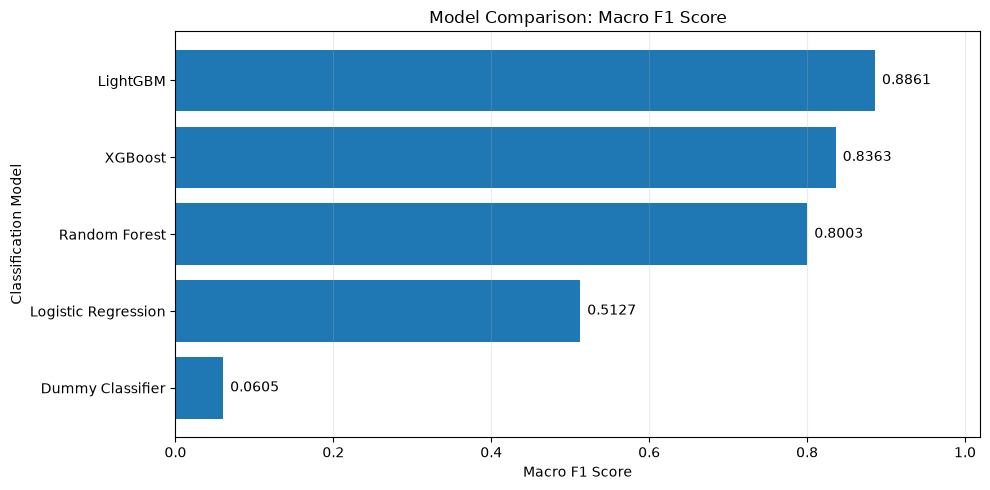

Figure saved: 03_macro_f1_comparison.png


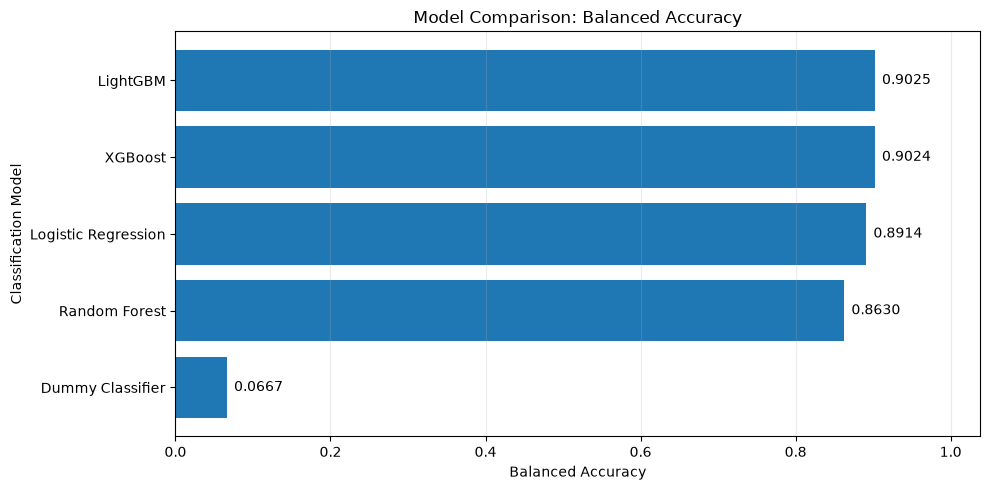

Figure saved: 03_balanced_accuracy_comparison.png


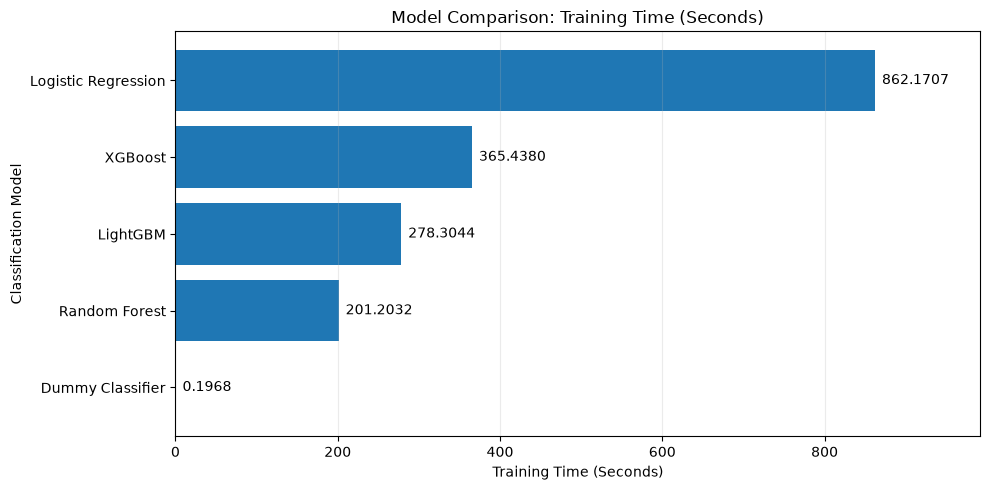

Figure saved: 03_training_time_comparison.png


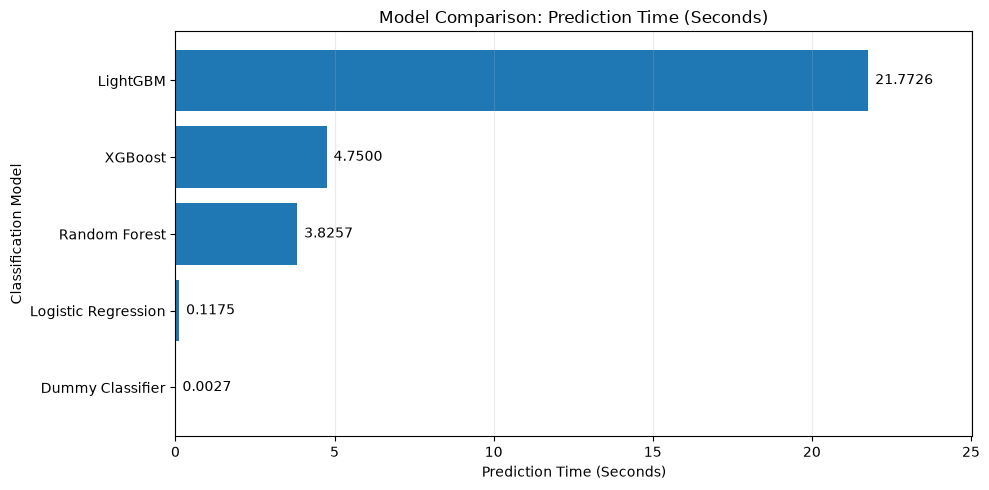

Figure saved: 03_prediction_time_comparison.png
-----------------------------------------------------------------
Total figures generated: 4
Figures directory: C:\Users\pc\XAI-Intrusion-Detection\figures
Model comparison visualization completed.


In [60]:
import matplotlib.pyplot as plt

figures_dir = PROJECT_ROOT / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

plot_metrics = [
    ("Macro_F1", "Macro F1 Score",
     "03_macro_f1_comparison.png"),
    
    ("Balanced_Accuracy", "Balanced Accuracy",
     "03_balanced_accuracy_comparison.png"),
    
    ("Training_Time_Seconds", "Training Time (Seconds)",
     "03_training_time_comparison.png"),
    
    ("Prediction_Time_Seconds", "Prediction Time (Seconds)",
     "03_prediction_time_comparison.png")
]

for metric, title, filename in plot_metrics:

    plot_data = model_comparison_df.sort_values(
        metric, ascending=True
    )

    fig, ax = plt.subplots(figsize=(10, 5))

    bars = ax.barh(
        plot_data["Model"],
        plot_data[metric]
    )

    ax.bar_label(
        bars,
        fmt="%.4f",
        padding=5
    )

    ax.set_title(f"Model Comparison: {title}")
    ax.set_xlabel(title)
    ax.set_ylabel("Classification Model")
    ax.grid(axis="x", alpha=0.25)
    ax.margins(x=0.15)

    plt.tight_layout()

    plt.savefig(
        figures_dir / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Figure saved:", filename)

print("-" * 65)
print("Total figures generated:", len(plot_metrics))
print("Figures directory:", figures_dir)
print("Model comparison visualization completed.")

## Best Model Selection

The best-performing model is selected based on Macro F1
obtained from the validation partition.

Macro F1 assigns equal importance to all 15 traffic
classes, making it suitable for evaluating performance
on the highly imbalanced CICIDS2017 dataset.

The selected model will undergo independent test
evaluation and explainability analysis in subsequent
notebooks.

The independent test partition is not used during
model selection.

In [61]:
print("BEST MODEL SELECTION")
print("-" * 65)

ranked_models = model_comparison_df.sort_values(
    "Macro_F1", ascending=False
)

best_model_record = ranked_models.iloc[0]

selected_model_name = best_model_record["Model"]

model_file_mapping = {
    "Dummy Classifier": "03_dummy_classifier.joblib",
    "Logistic Regression": "03_logistic_regression.joblib",
    "Random Forest": "03_random_forest.joblib",
    "XGBoost": "03_xgboost.joblib",
    "LightGBM": "03_lightgbm.joblib"
}

selected_model_path = (
    models_dir / model_file_mapping[selected_model_name]
)

assert selected_model_path.exists(), "Selected model file missing."

selected_model = joblib.load(selected_model_path)

model_selection_summary = {
    "selected_model": selected_model_name,
    "selection_metric": "Macro_F1",
    "validation_macro_f1": float(best_model_record["Macro_F1"]),
    "validation_accuracy": float(best_model_record["Accuracy"]),
    "validation_balanced_accuracy": float(
        best_model_record["Balanced_Accuracy"]
    ),
    "validation_weighted_f1": float(
        best_model_record["Weighted_F1"]
    ),
    "training_time_seconds": float(
        best_model_record["Training_Time_Seconds"]
    ),
    "prediction_time_seconds": float(
        best_model_record["Prediction_Time_Seconds"]
    ),
    "model_path": str(selected_model_path.relative_to(PROJECT_ROOT)),
    "number_of_features": EXPECTED_FEATURES,
    "number_of_classes": EXPECTED_CLASSES,
    "random_state": RANDOM_STATE,
    "independent_test_used_for_selection": False
}

selection_path = CONFIG_DIR / "03_selected_model.json"

with open(selection_path, "w", encoding="utf-8") as file:
    json.dump(model_selection_summary, file, indent=4)

display(
    pd.DataFrame([model_selection_summary]).T
)

print("-" * 65)
print("Selected model:", selected_model_name)
print("Model loading successful:", True)
print("Selection configuration saved:", selection_path)
print("Best model selection completed.")

BEST MODEL SELECTION
-----------------------------------------------------------------


,0
selected_model,LightGBM
selection_metric,Macro_F1
validation_macro_f1,0.886062
validation_accuracy,0.998636
validation_balanced_accuracy,0.902456
validation_weighted_f1,0.998686
training_time_seconds,278.304374
prediction_time_seconds,21.772592
model_path,models\03_lightgbm.joblib
number_of_features,69


-----------------------------------------------------------------
Selected model: LightGBM
Model loading successful: True
Selection configuration saved: C:\Users\pc\XAI-Intrusion-Detection\config\03_selected_model.json
Best model selection completed.


## Final Artifact Verification

This section verifies that the trained models,
evaluation results, comparison figures and model
selection configuration have been successfully saved.

Artifact verification supports reproducibility
and ensures that subsequent experimental stages
can access the required resources.

In [62]:
print("FINAL ARTIFACT VERIFICATION")
print("-" * 65)

required_artifacts = [
    models_dir / "03_dummy_classifier.joblib",
    models_dir / "03_logistic_regression.joblib",
    models_dir / "03_random_forest.joblib",
    models_dir / "03_xgboost.joblib",
    models_dir / "03_lightgbm.joblib",
    RESULTS_DIR / "03_baseline_model_results.csv",
    RESULTS_DIR / "03_logistic_regression_results.csv",
    RESULTS_DIR / "03_random_forest_results.csv",
    RESULTS_DIR / "03_xgboost_results.csv",
    RESULTS_DIR / "03_lightgbm_results.csv",
    RESULTS_DIR / "03_model_comparison.csv",
    CONFIG_DIR / "03_selected_model.json"
]

figure_files = sorted(
    (PROJECT_ROOT / "figures").glob("03_*.png")
)

required_artifacts.extend(figure_files)

artifact_records = []

for artifact_path in required_artifacts:
    exists = artifact_path.is_file()
    size = artifact_path.stat().st_size if exists else 0

    artifact_records.append({
        "Artifact": artifact_path.name,
        "Exists": exists,
        "Size_Bytes": size,
        "Status": "PASS" if exists and size > 0 else "FAIL"
    })

final_artifact_df = pd.DataFrame(artifact_records)

display(final_artifact_df)

all_artifacts_verified = bool(
    final_artifact_df["Status"].eq("PASS").all()
    and len(figure_files) >= 4
)

final_artifact_df.to_csv(
    RESULTS_DIR / "03_artifact_verification.csv",
    index=False
)

print("-" * 65)
print("Total artifacts checked:", len(final_artifact_df))
print("Figures verified:", len(figure_files))
print("All artifacts verified:", all_artifacts_verified)
print("Selected model:", selected_model_name)

assert all_artifacts_verified, "Artifact verification failed."

print("Notebook 03 completed successfully.")

FINAL ARTIFACT VERIFICATION
-----------------------------------------------------------------


,Artifact,Exists,Size_Bytes,Status
0,03_dummy_classifier.joblib,True,799,PASS
1,03_logistic_regression.joblib,True,5331,PASS
2,03_random_forest.joblib,True,43291041,PASS
3,03_xgboost.joblib,True,3017086,PASS
4,03_lightgbm.joblib,True,5399436,PASS
5,03_baseline_model_results.csv,True,307,PASS
6,03_logistic_regression_results.csv,True,316,PASS
7,03_random_forest_results.csv,True,295,PASS
8,03_xgboost_results.csv,True,289,PASS
9,03_lightgbm_results.csv,True,290,PASS


-----------------------------------------------------------------
Total artifacts checked: 16
Figures verified: 4
All artifacts verified: True
Selected model: LightGBM
Notebook 03 completed successfully.


## Conclusion

Five classification models were developed and evaluated
using the CICIDS2017 dataset:

- Dummy Classifier
- Logistic Regression
- Random Forest
- XGBoost
- LightGBM

The experimental development partition contained
1,613,310 records, while the validation partition
contained 403,328 records across 69 features
and 15 traffic classes.

LightGBM achieved the highest validation Macro F1
score of 0.886062 and was selected for subsequent
independent evaluation and explainability analysis.

Its validation accuracy was 99.8636%, with a
balanced accuracy of 90.2456%.

The Logistic Regression model did not achieve
convergence under the configured training conditions.
This limitation should be considered when interpreting
the comparative results.

The independent test partition was not used for
model selection.

The next experimental stage will evaluate the
selected model on the independent test partition
and examine its class-level detection performance.

## Development Preprocessing Artifact Persistence

The development-specific preprocessing parameters
are preserved to ensure consistent transformation
of the independent test dataset and reproducibility
of subsequent explainability analysis.

In [63]:
print("DEVELOPMENT PREPROCESSING ARTIFACT PERSISTENCE")
print("-" * 65)

development_artifacts = {
    "03_development_scaler.joblib":
        development_scaler,

    "03_development_replacement_values.joblib":
        development_replacement_values,

    "03_development_feature_names.joblib":
        development_feature_names,

    "03_development_transform_replacements.joblib":
        development_transform_replacements,

    "03_development_sentinel_features.joblib":
        development_sentinel_features
}

for filename, artifact in development_artifacts.items():
    artifact_path = RESULTS_DIR / filename
    joblib.dump(artifact, artifact_path)

    print(
        filename,
        "| Saved:", artifact_path.is_file()
    )

np.save(
    RESULTS_DIR / "03_development_indices.npy",
    development_indices
)

np.save(
    RESULTS_DIR / "03_validation_indices.npy",
    validation_indices
)

print("-" * 65)
print("Scaler fitted records:",
      development_scaler.n_samples_seen_)

print("Development records:", len(development_indices))
print("Validation records:", len(validation_indices))

assert development_scaler.n_samples_seen_ == 1613310

print("-" * 65)
print("Development preprocessing artifacts saved successfully.")

DEVELOPMENT PREPROCESSING ARTIFACT PERSISTENCE
-----------------------------------------------------------------
03_development_scaler.joblib | Saved: True
03_development_replacement_values.joblib | Saved: True
03_development_feature_names.joblib | Saved: True
03_development_transform_replacements.joblib | Saved: True
03_development_sentinel_features.joblib | Saved: True
-----------------------------------------------------------------
Scaler fitted records: 1613310.0
Development records: 1613310
Validation records: 403328
-----------------------------------------------------------------
Development preprocessing artifacts saved successfully.
